# OPIM-5671 Team Project 2: Coming Clean - What Toronto Airbnb Reviews Reveal

- Instructor: Jaeung Sim (University of Connecticut)
- Course: OPIM 5671 Data Mining and Time Series Forecasting
- Team Seven Members: Matthew Koh, Preshitha Sureshkumar, James Eastwood, Rama Akach, Kaan Ates Boyaci, Luke Bauer
- Dataset: Inside Airbnb Toronto (vladimirkondratev/inside-airbnb-toronto-sep-2026 on Kaggle)

### 1. Executive Summary and Research Questions

Airbnb displays aggregate star ratings that are heavily compressed near the top of the scale, alongside a simple single-word search filter. Because of rating inflation and survivorship bias, static star scores often obscure operational failures, property deterioration over time, and the interplay between host hospitality and physical accommodation quality.

Following our Team Seven Proposal and the course project guidelines, this notebook investigates one primary research question and two follow-up questions:

1. Primary Research Question (Themes and Dissatisfaction): What themes appear in Toronto Airbnb guest reviews, and which are most common in reviews expressing dissatisfaction?
2. Longitudinal Property Trajectory Question (Reviews Changing Over Time): When linking individual guest reviews chronologically to specific properties over time, how do review sentiment and complaint themes evolve to expose deteriorating properties versus turnaround properties that static cumulative ratings mask?
3. The Michelin Star Host Interaction Question: How relevant is a guest's personal interaction with the host (measured via normalized host name mentions in text and communication ratings) to the overall rating and sentiment of an Airbnb listing compared to physical property attributes (cleanliness, accuracy, location, and value)?

- Primary method: LDA topic modeling on review word counts, with TF-IDF as the supporting representation.
- Supporting analysis: Comparisons across groups (dissatisfied versus satisfied reviews, host mentioned versus not mentioned, and single-unit versus multi-unit hosts) and over time (early versus recent reviews of the same listing), validated with representative review texts. All findings represent observed associations rather than causal effects.

### 2. Intended Decision-Makers and Practical Value

1. Airbnb (Platform Quality and Trust)
   - Key problem: Based on complaints, which listings are poor or deteriorating over time, and how can listing quality and search filters be improved?
   - How findings inform action: Use rolling recent-review complaint signals per listing to flag properties whose recent reviews diverge from their lifetime star average, and upgrade search filters to account for negated phrases.
2. Hosts (Property Operations)
   - Key problem: Based on customer sentiment, is a listing performing well or poorly, and what should be fixed first?
   - How findings inform action: Prioritize the physical unit-operations issues (bathroom, bed, kitchen, cleanliness, and maintenance) that dominate dissatisfied reviews, set accurate expectations in the listing description, and keep host communication personal and responsive.
3. Customers and Guests (Booking Decisions)
   - Key problem: Based on glowing reviews versus hidden text complaints, how can guests identify genuinely good listings?
   - How findings inform action: Look beyond high lifetime averages by inspecting recent chronological reviews for negation-bound complaint phrases and commercial multi-unit host warning signs.

### 3. Alignment with Team Seven's 10-Step Analytical Plan

1. Step 1 (Preprocessing and English-only filter): Strip HTML line-break artifacts, drop missing or duplicate texts, and apply a deterministic rule-based English filter rather than machine-translating foreign reviews.
2. Step 2 (Join host name and listing ratings by listing ID): Inner-join the reviews table with the listings metadata table by listing ID to link every review to property ratings, neighborhood, Superhost status, host listing count, and longitudinal timelines.
3. Step 3 (Bag-of-Words representation): Construct sparse document-term count matrices fitted strictly on the training partition.
4. Step 4 (Tokenize, replace host name with a generic token, and anonymize reviewer name): Drop reviewer names for privacy, replace each listing's host name with a unified host name token, and track whether the host is mentioned by name.
5. Step 5 (Flag stop words that flip sentiments with valuable tokens): Preserve raw text for sentiment polarity scoring, and bind sentiment-flipping negations (such as not, no, never) to the following content word to separate true complaints from double-negative praise.
6. Step 6 (Remove unnecessary stop words): Remove standard English stop words and domain boilerplate words, and compare the top token frequencies before versus after filtering.
7. Step 7 (Lemmatization and host nickname resolution): Apply part-of-speech-aware lemmatization and map common English nickname families to the unified host name token.
8. Step 8 (Calculate TF, IDF, then TF-IDF, plus Truncated SVD): Compute explicit term frequency, inverse document frequency, and TF-IDF tables, contrast dissatisfied versus satisfied vocabulary, and extract Truncated SVD components.
9. Step 9 (Perform LDA Topic Modeling): Fit Latent Dirichlet Allocation across candidate topic counts on training word counts, evaluate UMass coherence, and validate topic labels with representative reviews.
10. Step 10 (Cross-analyze TF-IDF with LDA, sentiment, emotions, time trajectories, and prediction): Cross-tabulate LDA topics with TF-IDF terms, sentiment polarity, emotion rates, longitudinal property drift, the Michelin Star host question, and regression models evaluated across training, validation, and test splits.


## 0. Colab Setup, Reproducibility Constants, and Helper Functions

This notebook runs end-to-end on a standard Google Colab CPU runtime or local Python environment. In accordance with course guidelines, we use lightweight, reproducible libraries, fix a global random seed, and print package versions for full reproducibility.


In [1]:
# Install lightweight dependencies if missing (compatible with both Google Colab and local Jupyter)
import importlib.metadata, importlib.util, subprocess, sys
for pkg_spec, mod_name in [('kagglehub', 'kagglehub'), ('nltk', 'nltk'), ('textblob==0.19.0', 'textblob'), ('nrclex==4.1.0', 'nrclex')]:
    if importlib.util.find_spec(mod_name) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg_spec])
    elif '==' in pkg_spec:
        pkg_name, expected_ver = pkg_spec.split('==', 1)
        if importlib.metadata.version(pkg_name) != expected_ver:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg_spec])

In [2]:
import os, re, time, random, hashlib, warnings, importlib.metadata
from pathlib import Path
from collections import Counter, defaultdict
from itertools import chain

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from textblob import TextBlob
from nrclex import NRCLex

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110

# Reproducibility and runtime bounds aligned with OPIM 5671 notebooks
SEED = 25
random.seed(SEED)
np.random.seed(SEED)

MAX_REVIEWS = 3000        # Stratified working sample for full NLP & predictive modeling
TOPIC_FIT_LIMIT = 1500    # Training subset cap for LDA fitting
TOPIC_WORD_LIMIT = 150    # Per-review token cap for topic modeling
MAX_TERMS = 2000          # Vocabulary cap for TF-IDF representation
MAX_COMPONENTS = 10       # Truncated SVD components
TOPIC_COUNTS = (2, 3, 4)  # Candidate topic numbers K evaluated via UMass coherence

EMOTIONS = ['anger', 'fear', 'anticipation', 'trust', 'surprise', 'sadness', 'joy', 'disgust']
EMOTION_COLS = [f'{e}_per100' for e in EMOTIONS]

pd.set_option('display.max_colwidth', 120)
for package in ['numpy', 'pandas', 'scikit-learn', 'nltk', 'textblob', 'nrclex']:
    print(f'{package:15s}: {importlib.metadata.version(package)}')


numpy          : 2.4.6
pandas         : 2.2.3
scikit-learn   : 1.6.1
nltk           : 3.9.1
textblob       : 0.19.0
nrclex         : 4.1.0


In [3]:
# Download required NLTK lexical resources (stopwords and WordNet lemmatizer)
for resource in ['stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(resource, quiet=True, raise_on_error=True)

# Course-standard helper functions for LDA inspection, UMass coherence, and regression evaluation
def top_words(model, vectorizer, n=10):
    terms = vectorizer.get_feature_names_out()
    return {f'Topic_{i+1}': list(terms[row.argsort(kind='mergesort')[-n:][::-1]])
            for i, row in enumerate(model.components_)}

def umass_coherence(model, counts, top_n=8):
    # UMass coherence uses document co-occurrence among each topic's top words.
    # Higher (less negative) values indicate stronger empirical word co-occurrence.
    present = (counts > 0).astype(np.int32).tocsc()
    scores = []
    for weights in model.components_:
        ids = weights.argsort(kind='mergesort')[-top_n:][::-1]
        pairs = []
        for m in range(1, len(ids)):
            for l in range(m):
                together = present[:, ids[m]].multiply(present[:, ids[l]]).sum()
                earlier = present[:, ids[l]].sum()
                pairs.append(np.log((float(together) + 1.0) / max(float(earlier), 1.0)))
        scores.append(np.mean(pairs))
    return float(np.mean(scores))

def new_lda(k):
    return LatentDirichletAllocation(
        n_components=k, learning_method='batch',
        max_iter=100, max_doc_update_iter=20, evaluate_every=-1,
        n_jobs=1, random_state=SEED
    )

def deterministic_sample(frame, n, tag, seed=SEED):
    # Hash unique (listing_id, id) keys so sampling is invariant to row order and pandas/numpy versions
    lids = frame['listing_id'].to_numpy()
    rids = frame['id'].to_numpy()
    hashes = np.array(
        [hashlib.sha256(f'{seed}:{tag}:{int(l)}:{int(r)}'.encode()).hexdigest() for l, r in zip(lids, rids)],
        dtype=object
    )
    take_pos = np.argsort(hashes, kind='mergesort')[:n]
    return frame.iloc[take_pos].copy()

def deterministic_stratified_group_split(frame, strata_col, group_col='listing_id', n_splits=5, tag='outer', seed=SEED):
    # Version-invariant StratifiedGroupKFold (5 folds, returns train/dev positions and fold-0 holdout positions)
    y = np.asarray(frame[strata_col])
    groups = np.asarray(frame[group_col])
    _, y_inv, y_cnt = np.unique(y, return_inverse=True, return_counts=True)
    uniq_groups, groups_inv, groups_cnt = np.unique(groups, return_inverse=True, return_counts=True)
    n_classes = len(y_cnt)

    # Order groups deterministically by SHA-256 hash so results match across Colab and local scikit-learn versions
    group_hashes = np.array(
        [hashlib.sha256(f'{seed}:{tag}:{int(g)}'.encode()).hexdigest() for g in uniq_groups],
        dtype=object
    )
    perm = np.argsort(group_hashes, kind='mergesort')

    y_counts_per_group = np.zeros((len(groups_cnt), n_classes))
    for cls_idx, grp_idx in zip(y_inv, groups_inv):
        y_counts_per_group[grp_idx, cls_idx] += 1

    y_counts_per_group = y_counts_per_group[perm]
    inv_perm = np.empty_like(perm)
    inv_perm[perm] = np.arange(perm.size)
    groups_inv = inv_perm[groups_inv]

    sorted_groups_idx = np.argsort(-np.std(y_counts_per_group, axis=1), kind='stable')
    y_counts_per_fold = np.zeros((n_splits, n_classes))
    groups_per_fold = defaultdict(set)

    for grp_idx in sorted_groups_idx:
        grp_y = y_counts_per_group[grp_idx]
        best_fold, min_eval, min_samples = None, np.inf, np.inf
        for fold in range(n_splits):
            y_counts_per_fold[fold] += grp_y
            std_per_class = np.std(y_counts_per_fold / y_cnt.reshape(1, -1), axis=0)
            y_counts_per_fold[fold] -= grp_y
            fold_eval = np.mean(std_per_class)
            samples_in_fold = np.sum(y_counts_per_fold[fold])
            if fold_eval < min_eval or (np.isclose(fold_eval, min_eval) and samples_in_fold < min_samples):
                min_eval, min_samples, best_fold = fold_eval, samples_in_fold, fold
        y_counts_per_fold[best_fold] += grp_y
        groups_per_fold[best_fold].add(int(grp_idx))

    holdout_pos = np.array([idx for idx, grp_idx in enumerate(groups_inv) if grp_idx in groups_per_fold[0]], dtype=int)
    dev_pos = np.array([idx for idx, grp_idx in enumerate(groups_inv) if grp_idx not in groups_per_fold[0]], dtype=int)
    return dev_pos, holdout_pos

def metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred)
    }

print('Helper functions and NLTK resources initialized successfully.')

Helper functions and NLTK resources initialized successfully.


## 1. Data Acquisition, Property Linkage (Step 2), and English-Only Filtering (Step 1)

### 1.1 Download Dataset via KaggleHub

We retrieve the Inside Airbnb Toronto dataset directly from Kaggle using KaggleHub. The archive contains both individual guest review texts timestamped over time and detailed property and host metadata.


In [4]:
import kagglehub

# Pin dataset version 5 for exact reproducibility across Colab and local runs
path = kagglehub.dataset_download("vladimirkondratev/inside-airbnb-toronto-sep-2026/versions/5")

print("Path to dataset files:", path)

data_dir = Path(path)
available_files = sorted(p.name for p in data_dir.glob('*'))
print("Files in dataset directory:", available_files)

100%|██████████| 110M/110M [00:00<00:00, 130MB/s] 


Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/vladimirkondratev/inside-airbnb-toronto-sep-2026/versions/5
Files in dataset directory: ['calendar.csv', 'listings.csv', 'listings_summary.csv', 'neighbourhoods.csv', 'neighbourhoods.geojson', 'reviews.csv', 'reviews_summary.csv']


### 1.2 Step 2 and Step 4a: Link Reviews to Properties and Anonymize Reviewer Names

Per Step 2 of our analytical plan, we join the reviews table to the listings table by listing ID. This links every guest review to:

- Host attributes: host ID, host name, Superhost status, and total listings managed by the host.
- Property attributes: listing title, neighborhood, room type, price, and total number of reviews.
- Property rating dimensions: overall rating, cleanliness, accuracy, check-in, communication, location, and value.

Per Step 4 of our analytical plan, we immediately drop the reviewer name column upon merging to anonymize guest personal information, while retaining the host name column so we can normalize host mentions in the review text into a generic host token.


In [5]:
t_load = time.perf_counter()
reviews_raw = pd.read_csv(data_dir / 'reviews.csv')

listing_cols = [
    'id', 'name', 'host_id', 'host_name', 'host_is_superhost',
    'neighbourhood_cleansed', 'room_type', 'price', 'number_of_reviews',
    'calculated_host_listings_count',
    'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness',
    'review_scores_checkin', 'review_scores_communication', 'review_scores_location',
    'review_scores_value'
]
listings_raw = pd.read_csv(data_dir / 'listings.csv', usecols=listing_cols, low_memory=False)

print(f'Raw reviews.csv shape : {reviews_raw.shape}')
print(f'Raw listings.csv shape: {listings_raw.shape}')
print(f'Date coverage         : {reviews_raw["date"].min()} to {reviews_raw["date"].max()}')
print(f'Missing comments      : {reviews_raw["comments"].isna().sum()}')

# Step 2: Inner join reviews with property & host metadata by listing_id == id
merged_df = reviews_raw.merge(
    listings_raw, left_on='listing_id', right_on='id', how='inner', suffixes=('', '_listing')
)

# Step 4a: Remove reviewer_name (unnecessary PII) and redundant listing key
merged_df = merged_df.drop(columns=['reviewer_name', 'id_listing'])
print(f'Merged corpus rows    : {len(merged_df):,} (100.0% match across {merged_df["listing_id"].nunique():,} unique listings)')
print(f'Load & join time      : {time.perf_counter() - t_load:.2f} seconds')


Raw reviews.csv shape : (729202, 6)
Raw listings.csv shape: (22050, 17)
Date coverage         : 2010-06-07 to 2026-09-18
Missing comments      : 103
Merged corpus rows    : 729,202 (100.0% match across 17,764 unique listings)
Load & join time      : 4.20 seconds


### 1.3 Step 1: HTML Artifact Removal and Executive Decision to Drop Non-English Reviews

Inspection of raw Airbnb reviews reveals two data-quality issues that must be resolved before tokenization:

1. HTML Line-Break Tags: Many raw reviews contain HTML line-break tags. If non-letters are simply replaced with spaces without stripping HTML tags first, the leftover tag fragment becomes one of the most frequent artificial tokens in the corpus.
2. Multilingual Reviews (Step 1 Executive Decision): Because Toronto is an international destination, reviews appear in multiple languages. Per Step 1 of our proposal, we make the executive decision to drop non-English reviews rather than machine-translating them. Machine translation alters idiomatic expressions, smooths over harsh complaint phrasing, and introduces synthetic vocabulary into lexicon-based sentiment and emotion scorers.

Below, we apply a fast, deterministic rule-based English filter that requires predominantly ASCII characters plus core English function words without foreign function-word markers. Because it is rule-based, it is approximate and can occasionally drop a short English review or retain a mixed-language review.


In [6]:
t_clean = time.perf_counter()
n_initial = len(merged_df)

# 1. Remove missing comments or missing target property rating
df_clean = merged_df.dropna(subset=['comments', 'review_scores_rating']).copy()
n_non_missing = len(df_clean)

# 2. Strip HTML <br/> tags and whitespace using Python's re engine (avoids pandas 2.x vs 3.0 Arrow/RE2 differences)
re_br = re.compile(r'<br\s*/?>')
re_ws = re.compile(r'\s+')
raw_comments = [str(t) for t in df_clean['comments']]
html_tag_count = sum(1 for t in raw_comments if '<br' in t.lower())
cleaned_comments = [re_ws.sub(' ', re_br.sub(' ', t)).strip() for t in raw_comments]
df_clean['comments'] = pd.Series(cleaned_comments, index=df_clean.index, dtype=object)
df_clean = df_clean.loc[df_clean['comments'].str.len() >= 15].copy()
n_after_html_len = len(df_clean)

# 3. Sort deterministically by unique (listing_id, id) key before dropping duplicate texts
df_clean = df_clean.sort_values(['listing_id', 'id'], kind='mergesort').drop_duplicates(subset=['comments']).copy()
n_unique_text = len(df_clean)

# 4. Step 1 Executive Decision: Deterministic English-only filter via Unicode-aware Python re
re_non_ascii = re.compile(r'[^\x00-\x7F]')
en_func_pattern = r'\b(?:the|and|was|very|great|stay|place|clean|good|nice|host|location|would|recommend|with|for|had|we|to|in|is|it|of)\b'
foreign_func_pattern = (
    r'\b(?:très|tres|pour|dans|avec|nous|vous|une|les|des|appartement|séjour|sejour|merci|hôte|parfait|'
    r'tout|mais|todo|muy|para|con|una|los|las|del|por|excelente|gracias|alojamiento|ubicación|ubicacion|'
    r'estancia|sehr|und|wir|das|die|der|mit|für|wohnung|muito|uma|ottimo|molto|della)\b'
)
re_en = re.compile(en_func_pattern, re.IGNORECASE)
re_foreign = re.compile(foreign_func_pattern, re.IGNORECASE)

comment_texts = df_clean['comments'].tolist()
is_english = np.array([
    ((0 if t.isascii() else len(re_non_ascii.findall(t))) / max(len(t), 1) <= 0.03)
    and bool(re_en.search(t))
    and not bool(re_foreign.search(t))
    for t in comment_texts
], dtype=bool)
dropped_non_english_examples = df_clean.loc[~is_english, ['listing_id', 'date', 'comments']].head(5)

df_en = df_clean.loc[is_english].copy()
df_en['comments'] = df_en['comments'].astype(object)
df_en['date'] = pd.to_datetime(df_en['date'], errors='coerce')
df_en['year'] = df_en['date'].dt.year
n_english = len(df_en)

funnel_df = pd.DataFrame([
    {'Stage': '0. Raw Merged Reviews (reviews.csv + listings.csv)', 'Rows': n_initial, 'Share_Retained_%': 100.0},
    {'Stage': '1. Non-Missing Text & Property Rating', 'Rows': n_non_missing, 'Share_Retained_%': round(100*n_non_missing/n_initial, 2)},
    {'Stage': f'2. Strip HTML <br/> ({html_tag_count:,} cleaned) & Length >= 15 chars', 'Rows': n_after_html_len, 'Share_Retained_%': round(100*n_after_html_len/n_initial, 2)},
    {'Stage': '3. Deduplicate Exact Review Texts', 'Rows': n_unique_text, 'Share_Retained_%': round(100*n_unique_text/n_initial, 2)},
    {'Stage': f'4. English-Only Filter ({n_unique_text - n_english:,} non-English dropped)', 'Rows': n_english, 'Share_Retained_%': round(100*n_english/n_initial, 2)},
])
print(f'Full-corpus cleaning completed in {time.perf_counter() - t_clean:.2f}s')
display(funnel_df)
print('\nSample Non-English Reviews Properly Excluded by Step 1 Filter:')
display(dropped_non_english_examples)

Full-corpus cleaning completed in 34.13s


,Stage,Rows,Share_Retained_%
0,0. Raw Merged Reviews (reviews.csv + listings.csv),729202,100.00
1,1. Non-Missing Text & Property Rating,729099,99.99
2,"2. Strip HTML <br/> (116,922 cleaned) & Length >= 15 chars",703779,96.51
3,3. Deduplicate Exact Review Texts,689963,94.62
4,"4. English-Only Filter (77,107 non-English dropped)",612856,84.04



Sample Non-English Reviews Properly Excluded by Step 1 Filter:


,listing_id,date,comments
27,27423,2011-08-09,Mon séjour de près de 7semaines chez Brent a été exceptionnel. Merci à Brent pour son hospitalité et sa joie de vivr...
77,40456,2011-07-12,Denis nous a accueilli dans un logement quasi neuf. Tout était parfait. Le tramway est à proximité et permet de se r...
98,40456,2012-06-06,"Appartement propre et trèsfonctionnel, à deux pas d'une ligne de cable car et d'un supermarché. Les photos correspon..."
106,40456,2014-04-01,"Ce fut très agréable d'habiter chez Dennis, d'autant plus que Dennis est très accommodant et sympathique : un homme ..."
108,40456,2014-12-08,"Notre hôte, Denis, a été très accueillant à notre arrivée. Denis nous a bien informé de toutes les particularités du..."


### 1.4 Data Reasoning, Rating Compression Bias, and Stratified Working Sample

Before sampling for our computationally intensive NLP and topic-modeling pipeline, we inspect the distribution of ratings and dissatisfaction across the cleaned English corpus:

- Severe Rating Compression (Selection and Survivorship Bias): Unlike product reviews where low star ratings are common, Airbnb listings show a heavily compressed rating distribution near the top of the scale. Poorly rated listings are removed from the platform or avoided by guests, and mutual host-guest rating visibility encourages polite reciprocity.
- Hidden Textual Dissatisfaction: Even when a listing's aggregate score is high, guests still document concrete complaints in the review text regarding cleanliness, odors, pests, broken fixtures, noise, or host responsiveness.
- Stratified Working Sample: In line with the project guideline to use a justified subset that runs smoothly on free computing resources, we retain the full cleaned English corpus for macro temporal trends and property-level longitudinal tracking, and construct a reproducible stratified working sample (oversampling lower-rated or complaint-flagged stays alongside standard stays) for token-level lemmatization, emotion extraction, TF-IDF and SVD, LDA topic modeling, and regression modeling.
- Fair Validation Protocol (Split by Listing ID): We reserve a held-out test set and split the remaining development reviews into training and validation partitions. Because our target variable (overall listing rating) is shared by all reviews of the same property, we split using grouped stratification by listing ID so that all reviews of a given property fall into a single partition. All text vectorizers, SVD, and LDA models are fitted exclusively on the training partition.
- Sampling Caveat: Because lower-rated and complaint-flagged reviews are deliberately oversampled in the working subset, dissatisfaction rates inside the working sample are higher than in the full Toronto corpus. We use the working sample to compare groups and themes rather than to estimate city-wide rates.
- Leakage Check: If reviews of the same listing appeared in both training and test partitions, a model could partly memorize listing-level ratings. The code below verifies that zero listings are shared across partitions.


Partition sizes: {'dev': 2400, 'train': 1919, 'validation': 481, 'test': 600}
Full English corpus listing rating: median = 4.88, mean = 4.84, reviews on listings rated < 4.50 = 2.6%
Complaint-cue rate: full English corpus = 2.1% | working sample = 14.4%
Listings per partition: train = 1443, validation = 361, test = 451 | listings shared across partitions = 0
Review share per partition (%): {'train': 64.0, 'validation': 16.0, 'test': 20.0}


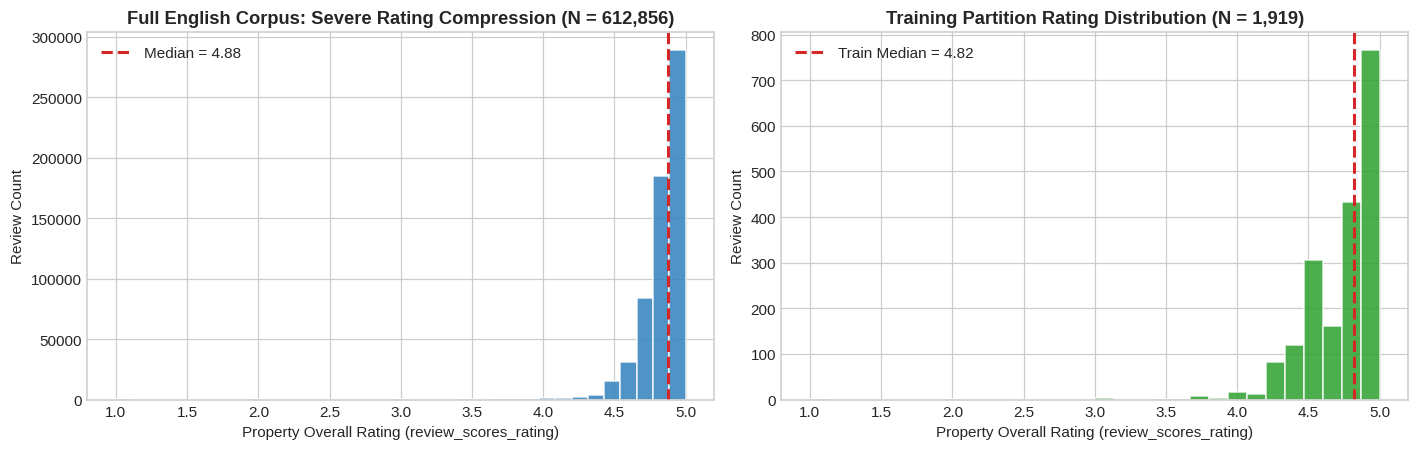

In [7]:
# Flag explicit dissatisfaction / complaint cues across the English corpus (Unicode-aware Python re)
dissat_lexicon_pattern = (
    r"\b(?:dirty|filthy|stain|stains|smell|smelled|odor|cockroach|roach|bedbug|mold|mould|"
    r"dusty|unclean|broken|freezing|unresponsive|rude|terrible|horrible|awful|disappointed|"
    r"disappointing|worst|refund|unacceptable|not clean|not working|never again|"
    r"would not recommend|do not stay|don't stay)\b"
)
re_dissat = re.compile(dissat_lexicon_pattern, re.IGNORECASE)
df_en['dissatisfied_cue'] = [bool(re_dissat.search(t)) for t in df_en['comments']]

# Construct deterministic hash-sampled working corpus of MAX_REVIEWS = 3,000 (invariant across Colab and local runs)
stratum_dissat_or_low = df_en.loc[(df_en['review_scores_rating'] < 4.55) | df_en['dissatisfied_cue']]
stratum_standard = df_en.loc[~df_en.index.isin(stratum_dissat_or_low.index)]

df_unsampled = pd.concat([
    deterministic_sample(stratum_dissat_or_low, 1200, tag='stratum_dissat'),
    deterministic_sample(stratum_standard, MAX_REVIEWS - 1200, tag='stratum_standard'),
])
df = deterministic_sample(df_unsampled, len(df_unsampled), tag='shuffle_working').reset_index(drop=True)
df.index.name = 'row_id'

# Create rating / satisfaction stratification key for train / validation / test split
df['strata_key'] = (
    df['dissatisfied_cue'].astype(str) + '_' +
    pd.qcut(df['review_scores_rating'], q=3, labels=['Low', 'Mid', 'High'], duplicates='drop').astype(str)
)

# Listing-level split: every listing's reviews go to exactly one partition (version-invariant grouped 5-fold holdout).
dev_pos, test_pos = deterministic_stratified_group_split(df, 'strata_key', n_splits=5, tag='outer')
dev, test = df.iloc[dev_pos].copy(), df.iloc[test_pos].copy()

train_pos, valid_pos = deterministic_stratified_group_split(dev, 'strata_key', n_splits=5, tag='inner')
train, valid = dev.iloc[train_pos].copy(), dev.iloc[valid_pos].copy()
test = test.copy()

assert set(train.index).isdisjoint(valid.index), 'Train and validation indices must be disjoint!'
assert set(dev.index).isdisjoint(test.index), 'Development and test indices must be disjoint!'
print('Partition sizes:', {'dev': len(dev), 'train': len(train), 'validation': len(valid), 'test': len(test)})

# Data reasoning checks used in Section 1.4
print(f"Full English corpus listing rating: median = {df_en['review_scores_rating'].median():.2f}, "
      f"mean = {df_en['review_scores_rating'].mean():.2f}, "
      f"reviews on listings rated < 4.50 = {100 * (df_en['review_scores_rating'] < 4.50).mean():.1f}%")
print(f"Complaint-cue rate: full English corpus = {100 * df_en['dissatisfied_cue'].mean():.1f}% | "
      f"working sample = {100 * df['dissatisfied_cue'].mean():.1f}%")

# Leakage check: the target is listing-level, so no listing may appear in two partitions
shared_dev_test = set(dev['listing_id']) & set(test['listing_id'])
shared_train_valid = set(train['listing_id']) & set(valid['listing_id'])
assert not shared_dev_test and not shared_train_valid, 'A listing appears in more than one partition!'
print(f"Listings per partition: train = {train['listing_id'].nunique()}, validation = {valid['listing_id'].nunique()}, "
      f"test = {test['listing_id'].nunique()} | listings shared across partitions = 0")
print('Review share per partition (%):', {name: round(100 * len(part) / len(df), 1)
      for name, part in [('train', train), ('validation', valid), ('test', test)]})

# Visualize full-corpus rating compression vs working sample rating distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(df_en['review_scores_rating'], bins=35, color='#3182bd', edgecolor='white', alpha=0.85)
axes[0].axvline(df_en['review_scores_rating'].median(), color='#d62728', linestyle='--', lw=2,
                label=f'Median = {df_en["review_scores_rating"].median():.2f}')
axes[0].set_title(f'Full English Corpus: Severe Rating Compression (N = {len(df_en):,})', fontweight='bold')
axes[0].set_xlabel('Property Overall Rating (review_scores_rating)')
axes[0].set_ylabel('Review Count')
axes[0].legend()

axes[1].hist(train['review_scores_rating'], bins=30, color='#2ca02c', edgecolor='white', alpha=0.85)
axes[1].axvline(train['review_scores_rating'].median(), color='#d62728', linestyle='--', lw=2,
                label=f'Train Median = {train["review_scores_rating"].median():.2f}')
axes[1].set_title(f'Training Partition Rating Distribution (N = {len(train):,})', fontweight='bold')
axes[1].set_xlabel('Property Overall Rating (review_scores_rating)')
axes[1].set_ylabel('Review Count')
axes[1].legend()
plt.tight_layout()
plt.show()

## 2. Custom Text Preprocessing: Host Nicknames (Steps 4 and 7), Sentiment-Flipping Negations (Step 5), Stopwords (Step 6), and Lemmatization (Step 7)

Following Steps 4, 5, 6, and 7 of Team Seven's proposal, we design a domain-aware text preprocessing pipeline tailored to Airbnb reviews:

1. Step 4 and Step 7 (Replacing Host Names and Nicknames with a Generic Host Token):
   - Guests frequently thank or criticize their host by first name. If left untreated, common first names act as noisy high-frequency tokens that fragment topic models by host identity rather than semantic theme.
   - Furthermore, per Step 7, guests often use a shortened nickname in their review when the host's profile lists a formal name (for example, Alex for Alexandra, Matt for Matthew, or Mike for Michael). Our lookup table maps common formal and nickname pairs for each review's specific host name and replaces every match with a unified host token, while recording an indicator for whether the host was mentioned by name for our Michelin Star host-interaction analysis. Name variants that are also ordinary English words (such as will, bill, grace, or joy) are excluded so normal English usage is not miscounted as a host mention.
2. Step 5 (Flagging Stop Words That Flip Sentiments with Valuable Tokens):
   - Standard stopword lists remove negation words such as not, no, never, and contractions ending in n't. In hospitality reviews, removing negations turns a complaint like "the apartment was not clean and the heater did not work" into "apartment clean heater work", inverting a complaint into positive words.
   - Conversely, guests also use double-negative praise (litotes) such as "did not disappoint", "would not hesitate to return", or "did not want to leave".
   - To preserve sentiment flips in our Bag-of-Words, TF-IDF, and LDA representations, we intercept negation modifiers and bind them to the following lemmatized content word as a compound token (such as not_clean, not_work, and not_recommend versus not_disappoint, not_hesitate, and not_want), while keeping the original unstripped review text intact for sentiment polarity scoring.
3. Step 6 and Step 7 (Stopword Removal and Lemmatization):
   - We apply WordNet lemmatization across verb and noun forms (so inflected forms collapse to their base lemma) and remove non-informative stop words and domain boilerplate words.


In [8]:
# Step 7: Bi-directional formal name <-> nickname lookup table for host_name normalization
NICKNAME_MAP = {
    'alexander': ['alex', 'sandy'], 'alexandra': ['alex', 'lexi'], 'michael': ['mike', 'mick'],
    'matthew': ['matt'], 'daniel': ['dan', 'danny'], 'david': ['dave'], 'christopher': ['chris'],
    'nicholas': ['nick'], 'elizabeth': ['liz', 'beth', 'eliza'], 'katherine': ['kate', 'kathy', 'katie'],
    'catherine': ['kate', 'cathy', 'katie'], 'robert': ['rob', 'bob', 'bobby'], 'william': ['will', 'bill', 'billy'],
    'thomas': ['tom', 'tommy'], 'jennifer': ['jen', 'jenny'], 'benjamin': ['ben'], 'samuel': ['sam'],
    'andrew': ['andy', 'drew'], 'stephanie': ['steph'], 'joshua': ['josh'], 'anthony': ['tony'],
    'joseph': ['joe', 'joey'], 'jonathan': ['jon'], 'rebecca': ['becky'], 'victoria': ['vicky', 'tori'],
    'richard': ['rick', 'dick'], 'charles': ['charlie', 'chuck'], 'patricia': ['pat', 'trish'],
    'steven': ['steve'], 'stephen': ['steve'], 'timothy': ['tim'], 'kenneth': ['ken', 'kenny'],
    'edward': ['ed', 'eddie'], 'ronald': ['ron'], 'jeffrey': ['jeff'], 'gregory': ['greg'],
    'deborah': ['deb', 'debbie'], 'susan': ['sue', 'suzie'], 'margaret': ['maggie', 'meg', 'peggy'],
    'jacqueline': ['jackie'], 'christina': ['chris', 'tina'], 'natalie': ['nat'], 'philip': ['phil']
}

# Step 5: Sentiment-flipping negation words excluded from naive stopword deletion
NEGATION_WORDS = {
    'not', 'no', 'never', 'neither', 'nor', 'hardly', 'barely',
    'wasnt', 'werent', 'isnt', 'arent', 'didnt', 'doesnt', 'dont',
    'couldnt', 'wouldnt', 'shouldnt', 'wont', 'cant', 'cannot'
}

# Step 6: Base English stopwords (minus negations) + Airbnb domain boilerplate words
base_stop_words = (set(stopwords.words('english')) | set(ENGLISH_STOP_WORDS)) - NEGATION_WORDS
domain_boilerplate = {
    'airbnb', 'toronto', 'stay', 'stayed', 'staying', 'place', 'also',
    'really', 'very', 'would', 'get', 'got', 'one', 'two', 'us'
}
ALL_STOP_WORDS = base_stop_words | domain_boilerplate

# Name variants that are also common English words are never treated as host mentions
AMBIGUOUS_NAME_WORDS = {
    'will', 'bill', 'pat', 'sue', 'rob', 'drew', 'sandy', 'chuck', 'dick', 'nat',
    'joy', 'grace', 'hope', 'faith', 'sunny', 'rose', 'summer', 'may', 'june',
    'star', 'king', 'love', 'happy', 'lucky', 'honey', 'sky', 'river', 'city'
}

lemmatizer = WordNetLemmatizer()

def lemmatize_token(word):
    # Apply verb lemmatization first (e.g. 'smelled'->'smell', 'working'->'work'), then noun lemmatization ('stains'->'stain')
    v_lemma = lemmatizer.lemmatize(word, pos='v')
    return lemmatizer.lemmatize(v_lemma, pos='n')

def extract_host_variants(host_name):
    if pd.isna(host_name):
        return set()
    raw_parts = re.findall(r'[a-z]+', str(host_name).lower())
    non_name_words = {'and', 'the', 'group', 'home', 'homes', 'suites', 'suite', 'residence', 'property', 'management', 'inc', 'host', 'team', 'toronto', 'stay'}
    variants = {w for w in raw_parts if len(w) >= 3 and w not in ALL_STOP_WORDS and w not in non_name_words}
    for w in list(variants):
        if w in NICKNAME_MAP:
            variants.update(NICKNAME_MAP[w])
        for formal_name, nicks in NICKNAME_MAP.items():
            if w in nicks:
                variants.add(formal_name)
                variants.update(nicks)
    return variants - AMBIGUOUS_NAME_WORDS

def preprocess_review_row(row):
    text = str(row['comments'])
    host_variants = extract_host_variants(row['host_name'])

    # Normalize curly apostrophes and expand "n't" to " not" so contractions trigger negation binding
    normalized = text.lower().replace('’', "'").replace("n't", " not")
    alpha_only = re.sub(r'[^a-z\s]', ' ', normalized)
    raw_tokens = word_tokenize(alpha_only, preserve_line=True)

    # Step 4 & Step 7: Replace host_name and nickname matches with generic 'host_name_token'
    host_replaced = []
    host_mentions = 0
    for tok in raw_tokens:
        if tok in host_variants:
            host_replaced.append('host_name_token')
            host_mentions += 1
        else:
            host_replaced.append(tok)

    # Step 5, 6, 7: Bind negation flips ('not_<lemma>') and lemmatize remaining content words
    processed_tokens = []
    neg_count = 0
    i = 0
    while i < len(host_replaced):
        tok = host_replaced[i]
        if tok in NEGATION_WORDS:
            neg_count += 1
            bound = False
            for j in range(i + 1, min(i + 4, len(host_replaced))):
                nxt = host_replaced[j]
                if nxt not in ALL_STOP_WORDS and nxt not in NEGATION_WORDS and nxt != 'host_name_token' and len(nxt) > 2:
                    lemma_nxt = lemmatize_token(nxt)
                    processed_tokens.append(f'not_{lemma_nxt}')
                    i = j + 1
                    bound = True
                    break
            if not bound:
                processed_tokens.append('not_token')
                i += 1
        elif tok == 'host_name_token':
            processed_tokens.append('host_name_token')
            i += 1
        elif tok not in ALL_STOP_WORDS and len(tok) > 2:
            lemma_tok = lemmatize_token(tok)
            if lemma_tok not in ALL_STOP_WORDS and len(lemma_tok) > 2:
                processed_tokens.append(lemma_tok)
            i += 1
        else:
            i += 1

    return pd.Series({
        'tokenized': word_tokenize(text.lower(), preserve_line=True),
        'processed': ' '.join(processed_tokens[:TOPIC_WORD_LIMIT]),
        'host_mention_count': host_mentions,
        'mentions_host_name': int(host_mentions > 0),
        'negation_count': neg_count
    })

# Demonstrate the pipeline on synthetic Airbnb examples (Host Nickname + Negation Flip vs Naive Cleaning)
demo_examples = pd.DataFrame([
    {'host_name': 'Alexandra', 'comments': "Alex's apartment was super clean and everything worked!"},
    {'host_name': 'Alexandra', 'comments': "Alex's apartment was NOT clean and the heater didn't work!"},
    {'host_name': 'Matthew & Sarah', 'comments': "Matt was responsive and the condo did not disappoint, would not hesitate to return!"}
])
demo_out = demo_examples.apply(preprocess_review_row, axis=1)
demo_comparison = pd.DataFrame({
    'Host_Name': demo_examples['host_name'],
    'Original_Review': demo_examples['comments'],
    'TextBlob_Polarity (Raw)': [round(TextBlob(t).sentiment.polarity, 4) for t in demo_examples['comments']],
    'Processed_Tokens (Host + Negation Preserved)': demo_out['processed']
})
display(demo_comparison)


,Host_Name,Original_Review,TextBlob_Polarity (Raw),Processed_Tokens (Host + Negation Preserved)
0,Alexandra,Alex's apartment was super clean and everything worked!,0.3958,host_name_token apartment super clean work
1,Alexandra,Alex's apartment was NOT clean and the heater didn't work!,-0.2292,host_name_token apartment not_clean heater not_work
2,Matthew & Sarah,"Matt was responsive and the condo did not disappoint, would not hesitate to return!",0.0000,host_name_token responsive condo not_disappoint not_hesitate return


In [9]:
# Apply custom preprocessing across train, valid, and test partitions (row-wise deterministic transformation)
t_prep = time.perf_counter()
for part_name, part_df in [('train', train), ('valid', valid), ('test', test)]:
    res = part_df.apply(preprocess_review_row, axis=1)
    for col in res.columns:
        part_df[col] = res[col]

# Also sync columns back to df and dev by index
for col in ['tokenized', 'processed', 'host_mention_count', 'mentions_host_name', 'negation_count']:
    df.loc[train.index, col] = train[col]
    df.loc[valid.index, col] = valid[col]
    df.loc[test.index, col] = test[col]
    dev.loc[train.index, col] = train[col]
    dev.loc[valid.index, col] = valid[col]

print(f'Processed {len(df):,} working reviews in {time.perf_counter() - t_prep:.2f}s')
print(f'Share of training reviews mentioning host by name/nickname: {100*train["mentions_host_name"].mean():.1f}%')
display(train[['listing_id', 'host_name', 'comments', 'processed', 'mentions_host_name', 'negation_count']].head(3))


Processed 3,000 working reviews in 2.03s
Share of training reviews mentioning host by name/nickname: 33.8%


,listing_id,host_name,comments,processed,mentions_host_name,negation_count
row_id,,,,,,
2,42376874,Amanda,Samantha’s home is simply just beautiful. My husband and I stayed here for a night as a little staycation and we tru...,samantha home simply beautiful husband night little staycation truly impress love longer period time charm home love...,0,1
3,6349559,Sabah,First let me start off by saying this was my first time ever using air bnb so I was a little hesitant initially. It ...,let start say time use air bnb little hesitant initially end great experience thank host_name_token provide instruct...,1,0
4,45275123,Meera,There was unexpected smell and it was lower than I expect,unexpected smell lower expect,0,0


### 2.1 Frequent Terms Before versus After Filtering and Top Negation-Bound Tokens

We compare the most frequent tokens in our training corpus before filtering (which is dominated by punctuation, articles, and prepositions) versus after filtering (where domain-meaningful concepts such as praise, host mentions, cleanliness, location, comfort, and walkability emerge clearly).

We also inspect the most frequent negation-bound tokens captured by Step 5, separating genuine operational complaint flips (such as not_work, not_recommend, and not_clean) from idiomatic double-negative praise (such as not_disappoint, not_issue, not_problem, and not_far), and print sample reviews for not_clean and not_want to verify how guests use negated phrases in context.

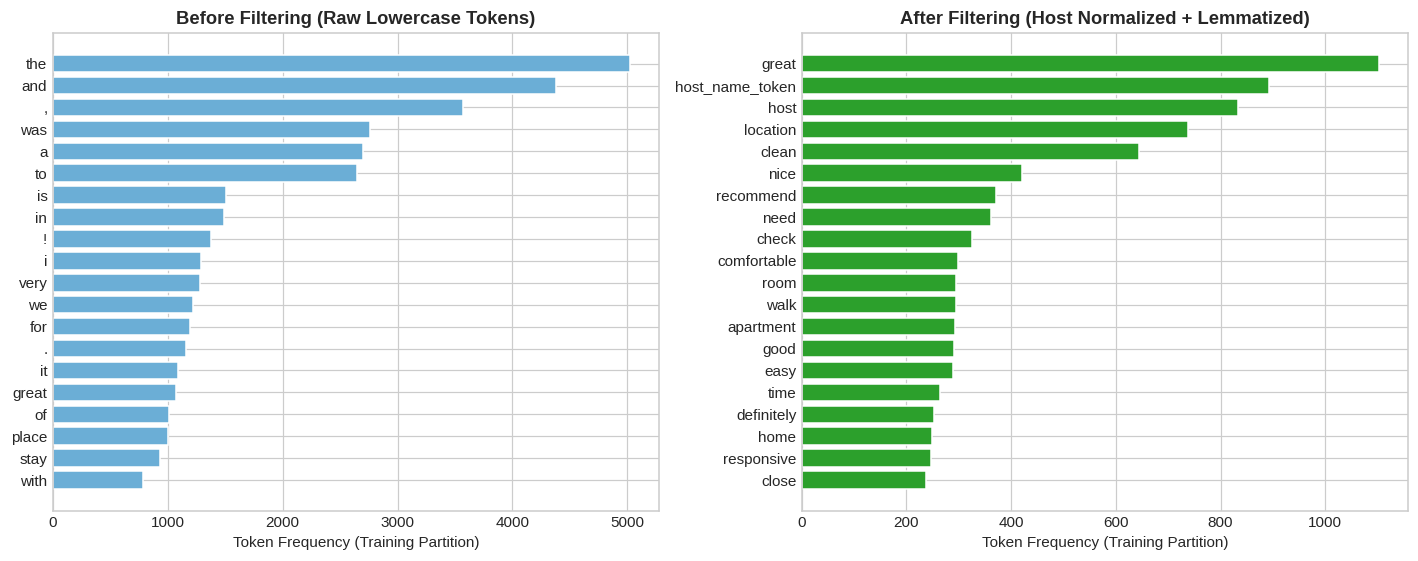

Unique raw tokens (train): 6,971 | Unique filtered tokens (train): 3,852

Step 5 Validation — Top 12 Negation-Bound Tokens in Training Reviews:


,Negation_Bound_Token,Train_Count,Semantic_Role
0,not_work,41,Dissatisfaction / Operational Complaint Flip
1,not_clean,31,Dissatisfaction / Operational Complaint Flip
2,not_recommend,26,Dissatisfaction / Operational Complaint Flip
3,not_disappoint,19,Litotes / Double-Negative Praise
4,not_issue,19,Litotes / Double-Negative Praise
5,not_use,16,Dissatisfaction / Operational Complaint Flip
6,not_ask,14,Dissatisfaction / Operational Complaint Flip
7,not_problem,13,Litotes / Double-Negative Praise
8,not_far,12,Litotes / Double-Negative Praise
9,not_expect,11,Dissatisfaction / Operational Complaint Flip



Representative Context Check (True Complaint Flip vs. Idiomatic Double-Negative Praise):
  [not_clean] (Listing Rating=4.92): We really enjoyed our stay at Ella's. Check-in went very smoothly, and the neighborhood is very safe. It's close to public transportation and several stores. The kitchen and dining...
  [not_want] (Listing Rating=4.86): The place is in a great location with a lot of restaurants and cafés around. Without a permit, parking is a bit tedious (we couldn’t park from 7-9AM on one street and then the othe...


In [10]:
before_counts = Counter(chain.from_iterable(train['tokenized']))
after_counts = Counter(chain.from_iterable(train['processed'].str.split()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, counts, title, color in zip(
    axes,
    [before_counts, after_counts],
    ['Before Filtering (Raw Lowercase Tokens)', 'After Filtering (Host Normalized + Lemmatized)'],
    ['#6baed6', '#2ca02c']
):
    top20 = counts.most_common(20)
    words, freqs = zip(*reversed(top20))
    ax.barh(words, freqs, color=color, edgecolor='white')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Token Frequency (Training Partition)')
plt.tight_layout()
plt.show()

print(f'Unique raw tokens (train): {len(before_counts):,} | Unique filtered tokens (train): {len(after_counts):,}')

# Inspect Top 12 Negation-Bound Tokens (Step 5) separating True Complaints vs Litotes Praise
litotes_praise_set = {
    'not_disappoint', 'not_hesitate', 'not_issue', 'not_problem',
    'not_far', 'not_bad', 'not_beat', 'not_want', 'not_wait'
}
neg_tokens = [w for w in chain.from_iterable(train['processed'].str.split()) if w.startswith('not_') and w != 'not_token']
neg_counts = Counter(neg_tokens).most_common(12)
neg_df = pd.DataFrame(neg_counts, columns=['Negation_Bound_Token', 'Train_Count'])
neg_df['Semantic_Role'] = neg_df['Negation_Bound_Token'].map(
    lambda x: 'Litotes / Double-Negative Praise' if x in litotes_praise_set
    else 'Dissatisfaction / Operational Complaint Flip'
)
print('\nStep 5 Validation — Top 12 Negation-Bound Tokens in Training Reviews:')
display(neg_df)

# Print representative examples contrasting a true complaint flip ('not_clean') vs idiomatic litotes praise ('not_want')
print('\nRepresentative Context Check (True Complaint Flip vs. Idiomatic Double-Negative Praise):')
for tok_label in ['not_clean', 'not_want']:
    matches = train.loc[train['processed'].str.contains(rf'\b{tok_label}\b', regex=True)]
    if len(matches):
        sample_row = matches.iloc[0]
        print(f"  [{tok_label}] (Listing Rating={sample_row['review_scores_rating']}): {sample_row['comments'][:180]}...")


## 3. Bag-of-Words (Step 3), Explicit TF, IDF, and TF-IDF Representation, and Truncated SVD (Step 8)

### 3.1 Step 3 and Step 8: Explicit Calculation of Term Frequency (TF), Inverse Document Frequency (IDF), and TF-IDF

Per Step 3 and Step 8 of our analytical plan, we construct both the Bag-of-Words count matrix and the TF-IDF matrix fitted strictly on the training partition:

- Term Frequency (TF): Measures how often a term appears in a review.
- Inverse Document Frequency (IDF): Downweights ubiquitous words that appear in a large fraction of reviews and boosts rare, diagnostic words such as specific cleanliness or maintenance complaints.
- TF-IDF: Multiplies term frequency by inverse document frequency (with row normalization) so that terms that are locally prominent within a specific review and globally distinctive across the corpus receive higher weight.


In [11]:
# Step 3 & Step 8: Fit Bag-of-Words (TF counts) and TF-IDF strictly on training reviews
bow_vectorizer = CountVectorizer(min_df=3, max_df=0.90, max_features=MAX_TERMS, token_pattern=r'[a-z_]+')
X_bow_train = bow_vectorizer.fit_transform(train['processed'])

tfidf_vectorizer = TfidfVectorizer(min_df=3, max_df=0.90, max_features=MAX_TERMS, token_pattern=r'[a-z_]+')
X_tfidf_train = tfidf_vectorizer.fit_transform(train['processed'])
X_tfidf_valid = tfidf_vectorizer.transform(valid['processed'])
X_tfidf_test = tfidf_vectorizer.transform(test['processed'])

terms = tfidf_vectorizer.get_feature_names_out()
assert X_tfidf_train.shape[0] == len(train)
print(f'Training Document-Term Matrix Shape : {X_tfidf_train.shape}')
print(f'Retained Vocabulary Size            : {len(terms):,}')
print(f'Matrix Sparsity (Zero Entries)      : {100 * (1 - X_tfidf_train.nnz / np.prod(X_tfidf_train.shape)):.2f}%')

# Build an explicit Step 8 breakdown table comparing TF, DF, IDF, and TF-IDF across key domain & complaint terms
term_to_idx = {t: i for i, t in enumerate(terms)}
total_tf = np.asarray(X_bow_train.sum(axis=0)).ravel()
doc_freq = np.asarray((X_bow_train > 0).sum(axis=0)).ravel()
idf_vals = tfidf_vectorizer.idf_
mean_tfidf = np.asarray(X_tfidf_train.mean(axis=0)).ravel()
mean_nonzero_tfidf = np.asarray(X_tfidf_train.sum(axis=0)).ravel() / np.maximum(doc_freq, 1)

focus_terms = [
    'great', 'host_name_token', 'clean', 'location', 'comfortable', 'walk',
    'dirty', 'smell', 'stain', 'not_work', 'not_clean', 'not_recommend', 'refund', 'noisy'
]
step8_rows = []
for t in focus_terms:
    if t in term_to_idx:
        idx = term_to_idx[t]
        step8_rows.append({
            'Term': t,
            'Category': 'Praise / Core Attribute' if t in {'great', 'host_name_token', 'clean', 'location', 'comfortable', 'walk'} else 'Dissatisfaction / Complaint',
            'Corpus_TF (Total Count)': int(total_tf[idx]),
            'Doc_Freq (DF)': int(doc_freq[idx]),
            'Doc_Share_%': round(100 * doc_freq[idx] / len(train), 2),
            'IDF_Weight': round(float(idf_vals[idx]), 3),
            'Mean_TFIDF (All Docs)': round(float(mean_tfidf[idx]), 4),
            'Mean_TFIDF (When Present)': round(float(mean_nonzero_tfidf[idx]), 3)
        })
step8_df = pd.DataFrame(step8_rows)
print('\nStep 8 Explicit Breakdown: TF, DF, IDF, and TF-IDF for Core vs. Complaint Vocabulary:')
display(step8_df)


Training Document-Term Matrix Shape : (1919, 1454)
Retained Vocabulary Size            : 1,454
Matrix Sparsity (Zero Entries)      : 98.81%

Step 8 Explicit Breakdown: TF, DF, IDF, and TF-IDF for Core vs. Complaint Vocabulary:


,Term,Category,Corpus_TF (Total Count),Doc_Freq (DF),Doc_Share_%,IDF_Weight,Mean_TFIDF (All Docs),Mean_TFIDF (When Present)
0,great,Praise / Core Attribute,1103,862,44.92,1.800,0.0813,0.181
1,host_name_token,Praise / Core Attribute,893,649,33.82,2.083,0.0547,0.162
2,clean,Praise / Core Attribute,645,603,31.42,2.157,0.0465,0.148
3,location,Praise / Core Attribute,738,690,35.96,2.022,0.0518,0.144
4,comfortable,Praise / Core Attribute,299,278,14.49,2.929,0.0270,0.187
5,walk,Praise / Core Attribute,294,246,12.82,3.051,0.0194,0.152
6,dirty,Dissatisfaction / Complaint,52,45,2.34,4.731,0.0043,0.183
7,smell,Dissatisfaction / Complaint,70,63,3.28,4.401,0.0062,0.188
8,stain,Dissatisfaction / Complaint,39,31,1.62,5.094,0.0031,0.192
9,not_work,Dissatisfaction / Complaint,41,38,1.98,4.897,0.0035,0.178


Interpretation of the TF to IDF to TF-IDF Progression:

- Common praise words appear in a large share of training reviews and therefore receive low IDF weights. Because they occur in so many documents, they still have the highest average TF-IDF when averaged across all reviews in the corpus.
- Specific complaint tokens (such as smell, dirty, stain, not_work, not_clean, not_recommend, refund, and noisy) appear in a much smaller fraction of reviews and receive much higher IDF weights.
- When a complaint term is actually present in a review, its average TF-IDF weight is comparable to or higher than that of common praise words. TF-IDF therefore keeps rare diagnostic complaint words visible inside the reviews where they occur, instead of letting common praise words dominate every vector.
- Caveat: Several explicit complaint words are also part of the lexicon used to flag dissatisfied reviews during stratified sampling, so their association with dissatisfaction is partly built in by design.

### 3.2 Inspect High-Weight TF-IDF Terms on Individual Reviews (False-Positive Check versus True Complaint)

We inspect the highest-weight TF-IDF terms for two concrete training reviews:

1. Lexicon False-Positive Check: A mixed-but-happy review of a high-rated listing that triggered the simple keyword flag because the guest noted minor wear and tear (such as carpet stains and paint chips) while explicitly clarifying that the unit was worn rather than dirty and did not hurt their stay, illustrating why isolated keyword flags can misfire without context.
2. True Dissatisfied Review Check: A genuine complaint review where both the complaint cue and negative sentiment polarity agree, demonstrating how TF-IDF surfaces specific physical and operational failure terms.


In [12]:
# 1. Lexicon False-Positive Check: first training row matching dissatisfied_cue
term_counts_row = X_tfidf_train.getnnz(axis=1)
cand_rows = np.flatnonzero((term_counts_row >= 6) & train['dissatisfied_cue'].to_numpy())
example_pos = int(cand_rows[0] if len(cand_rows) else np.argmax(term_counts_row))
example_idx = train.index[example_pos]

print(f'1. Lexicon False-Positive Check (row_id={example_idx}, listing_id={train.loc[example_idx, "listing_id"]}, listing rating={train.loc[example_idx, "review_scores_rating"]}):')
print(train.loc[example_idx, 'comments'])

row_vec = X_tfidf_train.getrow(example_pos)
order = np.argsort(row_vec.data)[::-1][:8]
example_terms = terms[row_vec.indices[order]]
display(pd.DataFrame({'Term': example_terms, 'TF_IDF_Weight': row_vec.data[order]}).round(3))

# Dense conversion limited to a 5-by-8 illustration (following Notebook 04)
small_slice = X_tfidf_train[:5, row_vec.indices[order]].toarray()
display(pd.DataFrame(
    small_slice,
    index=[f'Train Row {i}' for i in range(5)],
    columns=example_terms
).round(3))

# 2. True Dissatisfied Review Check: both complaint cue and negative polarity (< -0.10) agree
true_polarities = train['comments'].map(lambda t: TextBlob(str(t)).sentiment.polarity).to_numpy()
true_cand_rows = np.flatnonzero((term_counts_row >= 6) & train['dissatisfied_cue'].to_numpy() & (true_polarities < -0.10))
if len(true_cand_rows):
    true_pos = int(true_cand_rows[0])
    true_idx = train.index[true_pos]
    print(f'\n2. True Complaint Review Check (row_id={true_idx}, listing_id={train.loc[true_idx, "listing_id"]}, listing rating={train.loc[true_idx, "review_scores_rating"]}, polarity={true_polarities[true_pos]:+.3f}):')
    print(train.loc[true_idx, 'comments'])
    true_vec = X_tfidf_train.getrow(true_pos)
    true_order = np.argsort(true_vec.data)[::-1][:8]
    display(pd.DataFrame({'Term': terms[true_vec.indices[true_order]], 'TF_IDF_Weight': true_vec.data[true_order]}).round(3))


1. Lexicon False-Positive Check (row_id=18, listing_id=2988568, listing rating=4.8):
First off, the space is in a great location-- close to College St and Bathurst and the Annex. The space itself was fairly nice, although it was a lot more worn than I had expected from the photos-- upstairs was really nice, but downstairs had wear and tear (stains on carpet, chips in the paint on walls, etc.) None of this made the stay worse, but it took me a little bit to realize what was worn/dingy and not dirty first walking in. There were a few things that could have been cleaner, but nothing major. I will say that the toilet seat was worn and discolored and although clean still a little offputting. Basmattee was great about us arriving later than expected---good communication and I think overall it was a good value, especially with the location and parking included! Overall we were happy with our stay but I would have preferred the cleaners to be a little more thorough. I will say that I may pay m

,Term,TF_IDF_Weight
0,wear,0.497
1,little,0.258
2,cleaner,0.249
3,expect,0.216
4,say,0.204
5,realize,0.157
6,worse,0.157
7,overall,0.156


,wear,little,cleaner,expect,say,realize,worse,overall
Train Row 0,0.0,0.265,0.0,0.000,0.000,0.0,0.0,0.0
Train Row 1,0.0,0.188,0.0,0.000,0.223,0.0,0.0,0.0
Train Row 2,0.0,0.000,0.0,0.425,0.000,0.0,0.0,0.0
Train Row 3,0.0,0.000,0.0,0.000,0.000,0.0,0.0,0.0
Train Row 4,0.0,0.000,0.0,0.000,0.000,0.0,0.0,0.0



2. True Complaint Review Check (row_id=94, listing_id=965333876859866445, listing rating=4.0, polarity=-0.357):
The host advertised a two-bed room but gave us a tiny room with a single bed. Worst experience ever


,Term,TF_IDF_Weight
0,bed,0.424
1,tiny,0.422
2,room,0.404
3,single,0.393
4,worst,0.378
5,advertise,0.333
6,experience,0.235
7,host,0.126


### 3.3 Truncated SVD: Compact Continuous Features and Interpretation

We apply Truncated SVD to compress the sparse TF-IDF matrix into a small set of continuous latent components. Keep two methodological points in mind when reading the SVD table and chart below:

- Component signs are arbitrary: A negative loading represents an opposing lexical contrast rather than negative guest sentiment.
- Why the first SVD component can have lower explained variance than the second component and no negative loadings: Unlike standard PCA, Truncated SVD decomposes the sparse TF-IDF matrix without mean-centering. Because all TF-IDF entries are non-negative, the first singular vector points from the origin toward the average document centroid (resulting in all positive loadings), whereas the second component captures the largest spread of variance around the mean.
- Because a small number of linear components captures only a modest share of total lexical variance in a diverse review corpus, we use the SVD components as compact predictors in Section 7 rather than as standalone interpretable themes.


1454 TF-IDF term columns compressed into 10 SVD components in 0.05s.
Cumulative explained variance (10 components): 11.2%


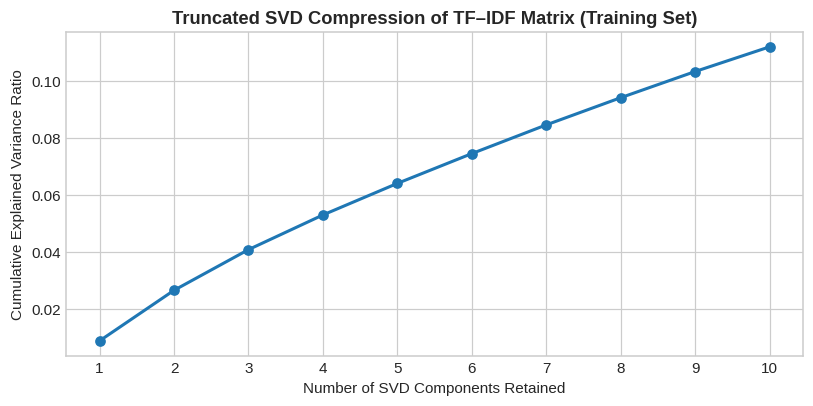

,Component,Explained_Var_%,Largest Positive Loadings,Most Negative Loadings
0,SVD_1,0.88,"great, host, location, host_name_token, clean, nice",(none)
1,SVD_2,1.77,"great, location, communication, host, view, value","host_name_token, comfortable, good, nice, like, room"
2,SVD_3,1.43,"good, nice, location, clean, check, value","host_name_token, recommend, amaze, definitely, highly, home"
3,SVD_4,1.21,"nice, host, friendly, host_name_token, thank, helpful","location, good, clean, perfect, comfortable, easy"


In [13]:
t_svd = time.perf_counter()
svd = TruncatedSVD(n_components=MAX_COMPONENTS, random_state=SEED)
X_svd_train = svd.fit_transform(X_tfidf_train)
X_svd_valid = svd.transform(X_tfidf_valid)
X_svd_test = svd.transform(X_tfidf_test)

svd_cols = [f'SVD_{i+1}' for i in range(MAX_COMPONENTS)]
svd_train_df = pd.DataFrame(X_svd_train, index=train.index, columns=svd_cols)
svd_valid_df = pd.DataFrame(X_svd_valid, index=valid.index, columns=svd_cols)
svd_test_df = pd.DataFrame(X_svd_test, index=test.index, columns=svd_cols)

cumulative_var = np.cumsum(svd.explained_variance_ratio_)
print(f'{X_tfidf_train.shape[1]} TF-IDF term columns compressed into {MAX_COMPONENTS} SVD components in {time.perf_counter()-t_svd:.2f}s.')
print(f'Cumulative explained variance (10 components): {cumulative_var[-1]:.1%}')

plt.figure(figsize=(7.5, 3.8))
plt.plot(np.arange(1, MAX_COMPONENTS + 1), cumulative_var, marker='o', color='#1f77b4', lw=2)
plt.xticks(np.arange(1, MAX_COMPONENTS + 1))
plt.xlabel('Number of SVD Components Retained')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.title('Truncated SVD Compression of TF–IDF Matrix (Training Set)', fontweight='bold')
plt.tight_layout()
plt.show()

# Inspect largest positive and most negative term loadings for the first 4 SVD components
loading_rows = []
for i, weights in enumerate(svd.components_[:4]):
    pos_idx = np.flatnonzero(weights > 0)
    neg_idx = np.flatnonzero(weights < 0)
    high_terms = pos_idx[np.argsort(weights[pos_idx])[-6:][::-1]]
    low_terms = neg_idx[np.argsort(weights[neg_idx])[:6]]
    loading_rows.append({
        'Component': svd_cols[i],
        'Explained_Var_%': round(100 * svd.explained_variance_ratio_[i], 2),
        'Largest Positive Loadings': ', '.join(terms[high_terms]),
        'Most Negative Loadings': ', '.join(terms[low_terms]) if len(low_terms) else '(none)'
    })
display(pd.DataFrame(loading_rows))


## 4. Sentiment Polarity and Normalized NRC Emotion Features

We extract two complementary lexicon-based feature families from the review texts:

1. Sentiment Polarity on Original Text: Scored using TextBlob on the original, unstripped review text so that negation modifiers, intensifiers, and punctuation remain intact. Polarity ranges from negative one (most negative) to positive one (most positive).
2. Normalized NRC Emotion Rates and Review Length: For each of the eight core NRC emotions (anger, fear, anticipation, trust, surprise, sadness, joy, and disgust), we compute the matched emotion word count per 100 lexical words. The denominator uses all lexical tokens before topic stopword removal so that emotion density is measured relative to total spoken verbosity. We also retain total review length as a separate feature because dissatisfied guests recounting multi-point grievances tend to write much longer reviews than satisfied guests leaving brief praise.


In [14]:
def word_tokens(text):
    # Lightweight lexical matching on original review text (consistent with Notebook 05 / Assignment #2)
    return re.findall(r"[a-z]+(?:'[a-z]+)?", str(text).lower().replace('’', "'"))

def sentiment_features(frame):
    # Score original review text, preserving negations, punctuation, and intensifiers
    return pd.DataFrame({
        'TextBlob_Sentiment': frame['comments'].map(lambda text: TextBlob(str(text)).sentiment.polarity)
    }, index=frame.index)

emotion_reader = NRCLex()  # Load bundled NRC lexicon once outside the row loop

def emotion_features(frame):
    records = []
    for text in frame['comments']:
        tokens = word_tokens(text)
        emotion_reader.load_token_list(tokens)
        counts = dict(emotion_reader.raw_emotion_scores)
        record = {'Review_Length': len(tokens)}
        record.update({
            f'{e}_per100': 100.0 * counts.get(e, 0) / max(len(tokens), 1)
            for e in EMOTIONS
        })
        records.append(record)
    return pd.DataFrame(records, index=frame.index)

def base_features(frame):
    return sentiment_features(frame).join(emotion_features(frame))

t_feat = time.perf_counter()
base_train = base_features(train)
base_valid = base_features(valid)
base_test = base_features(test)

# Attach sentiment and emotion columns to train/valid/test frames for cross-analysis
for part_df, b_df in [(train, base_train), (valid, base_valid), (test, base_test)]:
    for col in b_df.columns:
        part_df[col] = b_df[col]

# Define unified Dissatisfaction Indicator: either negative/near-zero polarity (< 0.05) or explicit complaint lexicon match
for part_df in (train, valid, test):
    part_df['is_dissatisfied'] = (part_df['TextBlob_Sentiment'] < 0.05) | part_df['dissatisfied_cue']

print(f'Extracted TextBlob sentiment and 8 NRC emotion rates in {time.perf_counter() - t_feat:.2f}s')
display(base_train.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(3))


Extracted TextBlob sentiment and 8 NRC emotion rates in 1.02s


,count,mean,std,min,50%,max
TextBlob_Sentiment,1919.0,0.396,0.224,-0.658,0.400,1.000
Review_Length,1919.0,48.892,48.335,2.000,33.000,496.000
anger_per100,1919.0,0.372,1.522,0.000,0.000,33.333
fear_per100,1919.0,0.327,1.132,0.000,0.000,14.286
anticipation_per100,1919.0,3.639,4.969,0.000,2.381,50.000
trust_per100,1919.0,6.303,6.685,0.000,4.545,50.000
surprise_per100,1919.0,1.841,4.019,0.000,0.000,50.000
sadness_per100,1919.0,0.889,2.216,0.000,0.000,28.571
joy_per100,1919.0,5.095,6.183,0.000,3.509,66.667
disgust_per100,1919.0,0.282,1.037,0.000,0.000,14.286


### 4.1 Empirical Comparison: Sentiment, Verbosity, and Emotion Rates in Satisfied versus Dissatisfied Reviews

Below we compare sentiment polarity, review length, negation counts, host-name mention rates, and the eight NRC emotion rates across satisfied versus dissatisfied training reviews, and plot the most distinctive TF-IDF terms that separate the two groups.

Measurement caveat: Because our unified dissatisfaction indicator flags reviews that have either low polarity or an explicit complaint keyword, differences in polarity, negation counts, and explicit complaint words between the two groups are partly built into the definition. Review length, emotion profiles, host-mention rates, and LDA topic mixtures provide the more informative comparisons.


,Satisfied_Reviews (Mean),Dissatisfied_Reviews (Mean),Relative_Ratio (Dissat / Sat)
TextBlob_Sentiment,0.451,0.114,0.253
Review_Length,40.132,94.355,2.351
negation_count,0.251,1.945,7.747
mentions_host_name,0.354,0.258,0.730
anger_per100,0.155,1.499,9.646
fear_per100,0.192,1.026,5.347
anticipation_per100,3.854,2.523,0.654
trust_per100,6.770,3.878,0.573
surprise_per100,1.956,1.240,0.634
sadness_per100,0.757,1.574,2.079


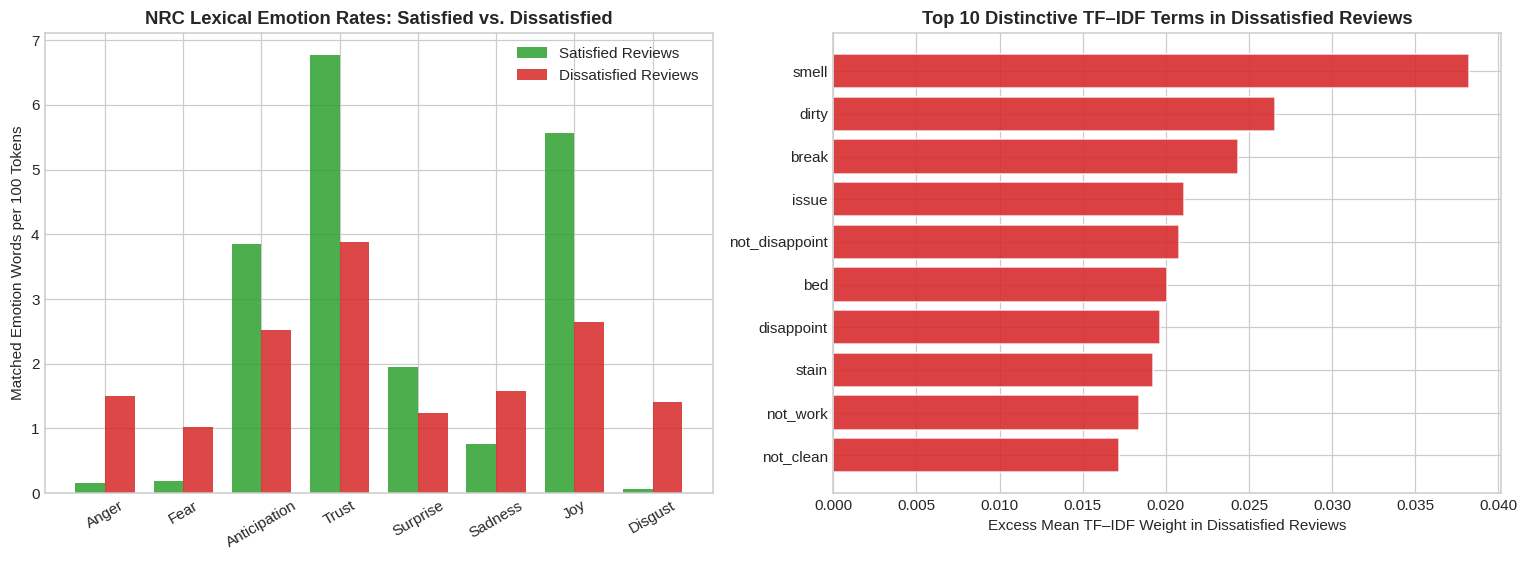

In [15]:
# Compare emotion rates, review length, and sentiment across Satisfied vs Dissatisfied reviews in train
emotion_summary = train.groupby('is_dissatisfied')[
    ['TextBlob_Sentiment', 'Review_Length', 'negation_count', 'mentions_host_name'] + EMOTION_COLS
].mean().T
emotion_summary.columns = ['Satisfied_Reviews (Mean)', 'Dissatisfied_Reviews (Mean)']
emotion_summary['Relative_Ratio (Dissat / Sat)'] = (
    emotion_summary['Dissatisfied_Reviews (Mean)'] / emotion_summary['Satisfied_Reviews (Mean)'].replace(0, np.nan)
)
display(emotion_summary.round(3))

# Plot NRC Emotion Rates & Distinctive TF-IDF Terms for Dissatisfied vs Satisfied Reviews
dissat_mask = train['is_dissatisfied'].to_numpy()
mean_tfidf_dissat = np.asarray(X_tfidf_train[dissat_mask].mean(axis=0)).ravel()
mean_tfidf_sat = np.asarray(X_tfidf_train[~dissat_mask].mean(axis=0)).ravel()
tfidf_diff = mean_tfidf_dissat - mean_tfidf_sat

top_dissat_idx = np.argsort(tfidf_diff)[-10:]
top_sat_idx = np.argsort(tfidf_diff)[:10][::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Left panel: 8 NRC Emotion Rates (Satisfied vs Dissatisfied)
x_pos = np.arange(len(EMOTIONS))
width = 0.38
sat_emo_means = [train.loc[~train['is_dissatisfied'], f'{e}_per100'].mean() for e in EMOTIONS]
dis_emo_means = [train.loc[train['is_dissatisfied'], f'{e}_per100'].mean() for e in EMOTIONS]

axes[0].bar(x_pos - width/2, sat_emo_means, width, label='Satisfied Reviews', color='#2ca02c', alpha=0.85)
axes[0].bar(x_pos + width/2, dis_emo_means, width, label='Dissatisfied Reviews', color='#d62728', alpha=0.85)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels([e.capitalize() for e in EMOTIONS], rotation=30)
axes[0].set_ylabel('Matched Emotion Words per 100 Tokens')
axes[0].set_title('NRC Lexical Emotion Rates: Satisfied vs. Dissatisfied', fontweight='bold')
axes[0].legend()

# Right panel: Top 10 Distinctive TF-IDF Terms in Dissatisfied Reviews
axes[1].barh(terms[top_dissat_idx], tfidf_diff[top_dissat_idx], color='#d62728', edgecolor='white', alpha=0.88)
axes[1].set_xlabel('Excess Mean TF–IDF Weight in Dissatisfied Reviews')
axes[1].set_title('Top 10 Distinctive TF–IDF Terms in Dissatisfied Reviews', fontweight='bold')

plt.tight_layout()
plt.show()


Interpretation of the Satisfied versus Dissatisfied Comparison:

- Review verbosity: Dissatisfied reviews are substantially longer on average than satisfied reviews, consistent with unhappy guests describing multiple operational problems in detail.
- Emotion shift: Dissatisfied reviews show sharply elevated rates of disgust, anger, fear, and sadness per 100 words, while satisfied reviews show much higher rates of joy, trust, anticipation, and surprise.
- Host mentions: Dissatisfied reviews mention the host by first name or nickname less frequently than satisfied reviews.
- Polarity and negations: Sentiment polarity is much lower and negation counts are much higher in dissatisfied reviews, though as noted above, these two measures partly reflect how the dissatisfaction indicator is constructed.


## 5. LDA Topic Modeling (Step 9) and Cross-Analysis with TF-IDF and Dissatisfaction (Step 10)

### 5.1 Step 9: Latent Dirichlet Allocation (LDA) on Word Counts and UMass Coherence Selection

We fit Latent Dirichlet Allocation on discrete word counts rather than TF-IDF weights, because LDA is a generative probabilistic model of word occurrences.

To prevent ubiquitous generic words (such as great, good, nice, clean, location, host, apartment, and room) from dominating every topic and making all topics look alike, we filter out high-frequency generic terms while retaining the normalized host token, specific property amenities, neighborhood and transit words, and all negation-bound tokens. We evaluate candidate topic counts on the training subset using UMass coherence alongside human interpretability of the top words.


LDA Count Matrix Shapes -> fit: (1500, 872) | train: (1919, 872) | valid: (481, 872)
K=2 fitted in 11.14s | UMass Coherence = -1.9286
K=3 fitted in 12.51s | UMass Coherence = -1.9089
K=4 fitted in 13.25s | UMass Coherence = -1.9594


,K,UMass,Seconds
0,2,-1.9286,11.1420
1,3,-1.9089,12.5142
2,4,-1.9594,13.2480


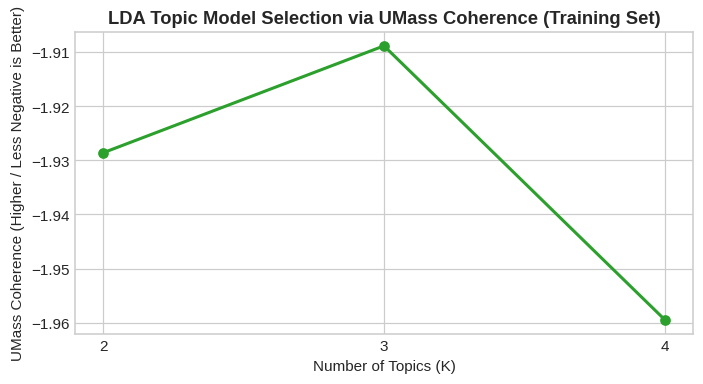


Top 10 Words per Topic for K=2:


,Topic_1,Topic_2
0,comfortable,night
1,easy,bed
2,walk,unit
3,check,leave
4,perfect,overall
5,thank,issue
6,amaze,bathroom
7,responsive,use
8,downtown,work
9,close,kitchen



Top 10 Words per Topic for K=3:


,Topic_1,Topic_2,Topic_3
0,amaze,walk,bed
1,comfortable,park,night
2,check,downtown,unit
3,thank,close,leave
4,responsive,restaurant,issue
5,beautiful,easy,overall
6,love,minute,bathroom
7,friendly,area,work
8,highly,away,day
9,helpful,distance,guest



Top 10 Words per Topic for K=4:


,Topic_1,Topic_2,Topic_3,Topic_4
0,thank,park,bed,easy
1,comfortable,walk,unit,check
2,lovely,area,night,walk
3,perfect,minute,bathroom,close
4,amaze,street,issue,downtown
5,friendly,thank,leave,restaurant
6,highly,car,shower,view
7,wonderful,check,work,comfortable
8,experience,thing,kitchen,helpful
9,love,use,guest,responsive


In [16]:
LDA_GENERIC_STOPS = {
    'great', 'good', 'nice', 'well', 'definitely', 'recommend', 'everything',
    'need', 'time', 'make', 'made', 'even', 'back', 'much', 'little', 'bit',
    'not_token', 'clean', 'location', 'host', 'apartment', 'room', 'home', 'house', 'condo'
}

def clean_for_lda(processed_str):
    return ' '.join(w for w in str(processed_str).split() if w not in LDA_GENERIC_STOPS)

topic_fit = deterministic_sample(train, min(TOPIC_FIT_LIMIT, len(train)), tag='topic_fit')
lda_vectorizer = CountVectorizer(
    preprocessor=clean_for_lda,
    max_features=1500, min_df=5, max_df=0.30,
    tokenizer=str.split, token_pattern=None, lowercase=False
)

counts_fit = lda_vectorizer.fit_transform(topic_fit['processed'])
counts_train = lda_vectorizer.transform(train['processed'])
counts_valid = lda_vectorizer.transform(valid['processed'])
counts_test = lda_vectorizer.transform(test['processed'])

print('LDA Count Matrix Shapes -> fit:', counts_fit.shape, '| train:', counts_train.shape, '| valid:', counts_valid.shape)

topic_models, topic_rows = {}, []
for k in TOPIC_COUNTS:
    started = time.perf_counter()
    lda_candidate = new_lda(k).fit(counts_fit)
    topic_models[k] = lda_candidate
    topic_rows.append({
        'K': k,
        'UMass': umass_coherence(lda_candidate, counts_fit),
        'Seconds': time.perf_counter() - started
    })
    print(f'K={k} fitted in {topic_rows[-1]["Seconds"]:.2f}s | UMass Coherence = {topic_rows[-1]["UMass"]:.4f}')

topic_scores = pd.DataFrame(topic_rows)
display(topic_scores.round(4))

plt.figure(figsize=(6.5, 3.6))
plt.plot(topic_scores['K'], topic_scores['UMass'], marker='o', color='#2ca02c', lw=2)
plt.xticks(TOPIC_COUNTS)
plt.xlabel('Number of Topics (K)')
plt.ylabel('UMass Coherence (Higher / Less Negative is Better)')
plt.title('LDA Topic Model Selection via UMass Coherence (Training Set)', fontweight='bold')
plt.tight_layout()
plt.show()

for k, model_k in topic_models.items():
    print(f'\nTop 10 Words per Topic for K={k}:')
    display(pd.DataFrame(top_words(model_k, lda_vectorizer, n=10)))


### 5.2 Selecting the Number of Topics, Validating Topic Mixtures on Representative Reviews, and Naming Themes

From the coherence curve and top-word tables above, we select the three-topic model (frozen before any test-set evaluation):

- Why two topics is too coarse: A two-topic model separates general comfort and location praise from everything else, merging physical unit details, nightly stays, and guest issues into a single broad second topic.
- Why four topics fragments themes: A four-topic model splits praise, neighborhood parking and walkability, and location and check-in convenience across multiple overlapping positive topics without yielding a cleaner problem cluster and lowers UMass coherence.
- Why three topics is selected: The three-topic model achieves the highest (least negative) UMass coherence score and gives a clean, parsimonious breakdown across three distinct stay dimensions:
  1. Topic 1 (Enthusiastic Praise and Host Appreciation): Focuses on overall comfort, smooth check-in, host responsiveness and friendliness, and warm guest gratitude.
  2. Topic 2 (Practical Stay Quality): Focuses on walkability, parking, downtown proximity, nearby restaurants, and practical neighborhood convenience.
  3. Topic 3 (Unit Operations and Problems): Focuses on beds, bathrooms, appliances working properly, nightly unit logistics, and operational stay issues.
- Note on automatic anchor-word labeling: Because LDA numbers topics arbitrarily across candidate runs, the code below maps each topic to a descriptive label programmatically using preset anchor words rather than hard-coding topic indices. With these three topics, the anchor-word scores align directly with the empirical top words of Topic 1, Topic 2, and Topic 3.

We then verify that every review's topic mixture sums to one and inspect the highest-weight training reviews for each topic.

In [17]:
# Select K = 3 based on thematic interpretability and coherence stability (frozen before test evaluation)
chosen_k = 3
lda = topic_models[chosen_k]
topic_cols = [f'Topic_{i+1}' for i in range(chosen_k)]
# LDA numbers topics arbitrarily, so assign each label from the topic's word weights
lda_terms = list(lda_vectorizer.get_feature_names_out())
topic_word_share = lda.components_ / lda.components_.sum(axis=1, keepdims=True)

def anchor_score(words):
    idx = [lda_terms.index(w) for w in words if w in lda_terms]
    return topic_word_share[:, idx].sum(axis=1)

ops_k = int(np.argmax(anchor_score(['bathroom', 'bed', 'issue', 'floor', 'unit', 'shower'])))
praise_scores = anchor_score(['beautiful', 'amaze', 'love', 'lovely', 'wonderful'])
praise_scores[ops_k] = -np.inf
praise_k = int(np.argmax(praise_scores))
practical_k = ({0, 1, 2} - {ops_k, praise_k}).pop()
TOPIC_LABELS = {
    f'Topic_{practical_k + 1}': f'Topic {practical_k + 1}: Practical Stay Quality',
    f'Topic_{praise_k + 1}': f'Topic {praise_k + 1}: Enthusiastic Praise & Host Appreciation',
    f'Topic_{ops_k + 1}': f'Topic {ops_k + 1}: Unit Operations & Problems'
}
print('Topic labels assigned from top words:', TOPIC_LABELS)

topic_train = pd.DataFrame(lda.transform(counts_train), columns=topic_cols, index=train.index)
topic_valid = pd.DataFrame(lda.transform(counts_valid), columns=topic_cols, index=valid.index)
topic_test = pd.DataFrame(lda.transform(counts_test), columns=topic_cols, index=test.index)

assert np.allclose(topic_train.sum(axis=1), 1.0)
assert np.allclose(topic_valid.sum(axis=1), 1.0)
assert np.allclose(topic_test.sum(axis=1), 1.0)

for col in topic_cols:
    train[col] = topic_train[col]
    valid[col] = topic_valid[col]
    test[col] = topic_test[col]

train['Dominant_Topic'] = topic_train.idxmax(axis=1).map(TOPIC_LABELS)
valid['Dominant_Topic'] = topic_valid.idxmax(axis=1).map(TOPIC_LABELS)
test['Dominant_Topic'] = topic_test.idxmax(axis=1).map(TOPIC_LABELS)

display(topic_train.head().round(3))

with pd.option_context('display.max_colwidth', 260):
    for t_col in topic_cols:
        top_ids = topic_train[t_col].nlargest(2).index
        print(f'\n=== Representative High-Weight Training Reviews for {TOPIC_LABELS[t_col]} ===')
        display(train.loc[top_ids, ['listing_id', 'review_scores_rating', 'TextBlob_Sentiment', 'comments']].join(topic_train.loc[top_ids, [t_col]]).round(3))


Topic labels assigned from top words: {'Topic_2': 'Topic 2: Practical Stay Quality', 'Topic_1': 'Topic 1: Enthusiastic Praise & Host Appreciation', 'Topic_3': 'Topic 3: Unit Operations & Problems'}


,Topic_1,Topic_2,Topic_3
row_id,,,
2,0.699,0.016,0.285
3,0.380,0.288,0.332
4,0.084,0.087,0.830
5,0.053,0.636,0.311
6,0.387,0.579,0.034



=== Representative High-Weight Training Reviews for Topic 1: Enthusiastic Praise & Host Appreciation ===


,listing_id,review_scores_rating,TextBlob_Sentiment,comments,Topic_1
row_id,,,,,
1276,810874888517812289,4.53,0.448,"I had an absolutely wonderful experience staying at Celine's place! The room and private bathroom were spotlessly clean—a top priority for me, and I was very impressed with the high standards of cleanliness maintained. The location was fantastic, and the o...",0.979
92,4930281,4.97,0.319,"Mayte was incredibly welcoming and made communication a breeze. As it was my first experience staying in an AirBnB, I had a few concerns, but she put me at ease right away. I also appreciate Balin the cat for his warm welcome and the way he made me feel at...",0.974



=== Representative High-Weight Training Reviews for Topic 2: Practical Stay Quality ===


,listing_id,review_scores_rating,TextBlob_Sentiment,comments,Topic_2
row_id,,,,,
2863,51104134,4.96,0.278,"Paul has curated a marvelous spot to land while traveling! We were on a long car trip across Canada and we stayed in this location for three days near the end of our trip, which afforded us the chance to catch our breath and restore our energy for the last...",0.983
403,1080121,4.64,0.341,"Kate's place was great! Close by to everything we needed for our stay. Overlooked the harbour front where many events took place. There's always something to do there! Sobeys and Longos grocery stores located a block away, Air Canada Centre and Rogers Cent...",0.979



=== Representative High-Weight Training Reviews for Topic 3: Unit Operations & Problems ===


,listing_id,review_scores_rating,TextBlob_Sentiment,comments,Topic_3
row_id,,,,,
1126,7610557,4.95,0.007,"First let me say that I’m not the complaining type. I’ve used Airbnb for about the past 18 months, and I travel about two weeks per month on business, usually splitting my overnights between hotels and Airbnb. I’ve had many many Airbnb stays in many differ...",0.992
1443,33494381,4.45,-0.006,"I can`t call this person a ""host"" but more of a home owner. She wakes up everyday at 5 30 am to take her cat out and keeps active making noise till 9 am then leave to work. during those three hours or so she goes frequently up and down the stairs, closes/o...",0.991


Validating the Topic Labels with Representative Reviews:

- Enthusiastic Praise and Host Appreciation (Topic 1): Supported by glowing representative reviews thanking warm, attentive hosts for spotless room and bathroom cleanliness, comfortable spaces, easy communication, and thoughtful welcoming touches such as a complimentary gift.
- Practical Stay Quality (Topic 2): Supported by detailed practical reviews describing convenient Toronto stays close to downtown landmarks, grocery stores, transit stations, restaurants, and laundromats alongside reliable host communication.
- Unit Operations and Problems (Topic 3): Supported by detailed complaint narratives documenting serious operational and house-rule breakdowns, such as a scheduled building water outage leaving guests unable to shower or flush the toilet paired with a deflecting host response, or repeated early-morning household noise in an uncomfortable tiny room.
- Why LDA catches complaints that lexicon sentiment misses: Notice in the table above that TextBlob assigns near-zero polarity scores (close to zero positive or negative) to the top complaint reviews in Topic 3. Because lexicon sentiment averages individual adjectives across long narratives (where neutral background sentences or positive side remarks such as "really comfortable" offset descriptions of water shutoffs, noise, and uncomfortable rooms), sentiment polarity alone can miss serious operational failures. By contrast, LDA assigns these reviews Topic 3 probabilities near one based on word co-occurrence, demonstrating why topic modeling adds essential value alongside sentiment scoring.
- Limitation: Every review is a mixture of topics, so assigning a single dominant topic simplifies longer reviews that discuss both positive and negative aspects of a stay.

### 5.3 Step 10: Cross-Analysis of LDA Topic Modeling with TF-IDF, Sentiment, Emotions, and Dissatisfaction (Finding 1)

Per Step 10 of our proposal and our Primary Research Question, we cross-analyze the three LDA themes against:

1. Dissatisfaction rate, mean sentiment polarity, and review length.
2. Lexical emotion rates (disgust and anger) and host-name mention rates.
3. Property sub-ratings (cleanliness and overall listing rating).
4. The most distinctive TF-IDF terms inside each dominant LDA topic cluster.


=== STEP 10: CROSS-ANALYSIS OF LDA TOPICS WITH TF–IDF, SENTIMENT, EMOTIONS, AND PROPERTY RATINGS ===


,LDA_Theme,Train_Reviews,Share_of_Corpus_%,Dissatisfied_Share_%,Mean_TextBlob_Polarity,Mean_Review_Length,Host_Name_Mention_%,Disgust_per100,Anger_per100,Listing_Cleanliness_Score,Listing_Overall_Rating,Distinctive_TFIDF_Terms (Step 10 Cross-Link)
0,Topic 1: Enthusiastic Praise & Host Appreciation,980,51.1,5.5,0.471,33.2,37.7,0.11,0.19,4.755,4.770,"host, great, host_name_token, amaze, thank, recommend, highly, friendly"
1,Topic 2: Practical Stay Quality,538,28.0,6.3,0.412,50.4,33.5,0.08,0.15,4.707,4.715,"walk, close, restaurant, park, station, subway, downtown, lot"
2,Topic 3: Unit Operations & Problems,401,20.9,55.4,0.194,85.2,24.9,0.97,1.12,4.602,4.625,"issue, unit, bed, night, room, floor, dirty, price"


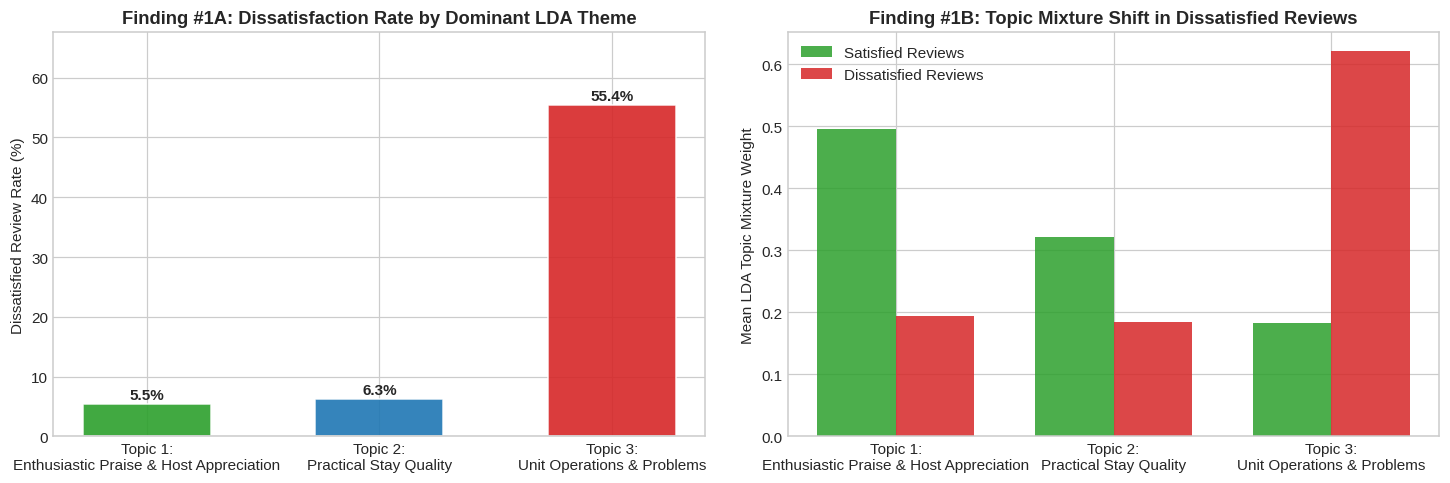

In [18]:
# Step 10 Cross-Analysis Table: LDA Dominant Topic vs Dissatisfaction, Sentiment, Emotions, Ratings, and Top TF-IDF Terms
cross_rows = []
for t_col in topic_cols:
    label = TOPIC_LABELS[t_col]
    mask = (train['Dominant_Topic'] == label).to_numpy()
    sub = train.loc[mask]

    # Compute top 8 distinctive TF-IDF terms inside this LDA topic cluster
    mean_tfidf_in = np.asarray(X_tfidf_train[mask].mean(axis=0)).ravel()
    mean_tfidf_out = np.asarray(X_tfidf_train[~mask].mean(axis=0)).ravel()
    top_tfidf_for_topic = terms[np.argsort(mean_tfidf_in - mean_tfidf_out)[-8:][::-1]]

    cross_rows.append({
        'LDA_Theme': label,
        'Train_Reviews': int(mask.sum()),
        'Share_of_Corpus_%': round(100 * mask.mean(), 1),
        'Dissatisfied_Share_%': round(100 * sub['is_dissatisfied'].mean(), 1),
        'Mean_TextBlob_Polarity': round(sub['TextBlob_Sentiment'].mean(), 3),
        'Mean_Review_Length': round(sub['Review_Length'].mean(), 1),
        'Host_Name_Mention_%': round(100 * sub['mentions_host_name'].mean(), 1),
        'Disgust_per100': round(sub['disgust_per100'].mean(), 2),
        'Anger_per100': round(sub['anger_per100'].mean(), 2),
        'Listing_Cleanliness_Score': round(sub['review_scores_cleanliness'].mean(), 3),
        'Listing_Overall_Rating': round(sub['review_scores_rating'].mean(), 3),
        'Distinctive_TFIDF_Terms (Step 10 Cross-Link)': ', '.join(top_tfidf_for_topic)
    })

cross_analysis_df = pd.DataFrame(cross_rows)
print('=== STEP 10: CROSS-ANALYSIS OF LDA TOPICS WITH TF–IDF, SENTIMENT, EMOTIONS, AND PROPERTY RATINGS ===')
display(cross_analysis_df)

# Visualize Finding #1: Dissatisfaction Rate and Mean Topic Weights in Satisfied vs Dissatisfied Reviews
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

short_labels = [TOPIC_LABELS[c].replace(': ', ':\n') for c in topic_cols]
dissat_rates = cross_analysis_df['Dissatisfied_Share_%'].values
theme_colors = {'Practical': '#1f77b4', 'Praise': '#2ca02c', 'Unit': '#d62728'}
bar_colors = [next(col for key, col in theme_colors.items() if key in TOPIC_LABELS[c]) for c in topic_cols]

axes[0].bar(short_labels, dissat_rates, color=bar_colors, edgecolor='white', width=0.55, alpha=0.9)
for i, v in enumerate(dissat_rates):
    axes[0].text(i, v + 0.8, f'{v:.1f}%', ha='center', fontweight='bold')
axes[0].set_ylabel('Dissatisfied Review Rate (%)')
axes[0].set_ylim(0, max(dissat_rates) * 1.22)
axes[0].set_title('Finding #1A: Dissatisfaction Rate by Dominant LDA Theme', fontweight='bold')

sat_topic_means = train.loc[~train['is_dissatisfied'], topic_cols].mean().values
dis_topic_means = train.loc[train['is_dissatisfied'], topic_cols].mean().values
x_idx = np.arange(len(topic_cols))
w = 0.36
axes[1].bar(x_idx - w/2, sat_topic_means, w, label='Satisfied Reviews', color='#2ca02c', alpha=0.85)
axes[1].bar(x_idx + w/2, dis_topic_means, w, label='Dissatisfied Reviews', color='#d62728', alpha=0.85)
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(short_labels)
axes[1].set_ylabel('Mean LDA Topic Mixture Weight')
axes[1].set_title('Finding #1B: Topic Mixture Shift in Dissatisfied Reviews', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


### Empirical Interpretation of Finding 1 (Themes and Dissatisfaction Cross-Analysis)

- Evidence:
  1. Dissatisfaction concentrates overwhelmingly in Topic 3 (Unit Operations and Problems): More than half of reviews dominated by Topic 3 express dissatisfaction, roughly nine to ten times the dissatisfaction rate of Topic 1 (Enthusiastic Praise and Host Appreciation) and Topic 2 (Practical Stay Quality), and Topic 3 rises sharply in mean mixture weight among dissatisfied reviews.
  2. Verbosity, emotion, and TF-IDF alignment: Compared with Topic 1 and Topic 2, Topic 3 reviews are more than two-and-a-half times as long on average as Topic 1 reviews, have the lowest mean sentiment polarity, the highest anger and disgust rates, and the lowest host-name mention rate, come from listings with the lowest cleanliness and overall ratings, and align with distinctive TF-IDF terms around unit failures and value friction (issue, unit, bed, night, room, floor, dirty, price).
  3. Positive and practical themes: Topic 1 (Enthusiastic Praise and Host Appreciation) accounts for slightly over half of training reviews, has the highest rate of personal host-name mentions, corresponds to listings with the highest cleanliness and overall ratings, and aligns with praise terms such as host, great, host_name_token, amaze, thank, recommend, highly, and friendly. Topic 2 (Practical Stay Quality) captures walkability, transit, and downtown neighborhood access (walk, close, restaurant, park, station, subway, downtown, lot) with low dissatisfaction and clean average scores.
- Interpretation: Guest dissatisfaction in Toronto Airbnb reviews centers squarely on unit-operation failures, hygiene issues, physical room and bed problems, and price-value friction (Topic 3), whereas satisfied reviews focus on warm host appreciation (Topic 1) and convenient neighborhood access (Topic 2).
- Credibility and limitations:
  1. Because the working sample oversamples lower-rated and complaint-flagged stays, the absolute dissatisfaction percentages in the table are higher than city-wide averages; the relative gap across topics is the key finding.
  2. The dissatisfaction indicator partly relies on complaint keywords and sentiment polarity.
  3. Dominant-topic assignment simplifies multi-theme reviews.
- Practical implication: Hosts and Airbnb quality teams should prioritize physical unit maintenance, bathroom and bedroom readiness, cleanliness, and fair value alongside responsive host communication, as failures in unit operations separate dissatisfied stays from praised ones.

## 6. Deep-Dive Empirical Findings: Property Reviews Changing Over Time and The Michelin Star Host Question

### 6.1 Finding 2: Linking Reviews to Particular Properties to Detect Quality Drift Over Time

A core motivation of our project is linking reviews to specific properties chronologically so we can observe property reviews changing over time. Static aggregate ratings on Airbnb weight a property's older reviews equally with its newest reviews. If a property experiences host burnout, deferred maintenance, or management turnover, its cumulative star rating can remain artificially high even while recent guests report worsening problems.

We examine temporal dynamics at two levels across the full cleaned English corpus:

1. Macro City-Wide Trajectory: Annual English review volume, active reviewed listings, and complaint-cue rates across Toronto over time.
2. Micro Property-Level Trajectory (Early-Career Half versus Recent-Career Half): For properties with at least 20 English reviews, we sort each listing's reviews chronologically by date, split each property's review history into its early half versus its recent half, and compute the shift in complaint-cue rate alongside total review count and active year span. We then plot rolling sentiment trajectories and inspect early versus recent review texts on specific case-study properties.


=== CITY-WIDE COMPLAINT-CUE RATE BY YEAR (2015-2026) ===


,year,Total_English_Reviews,Active_Reviewed_Listings,Dissatisfaction_Cue_Rate_Pct
0,2015,6009,615,1.43
1,2016,13629,1105,1.39
2,2017,24395,1642,1.27
3,2018,38382,2268,1.69
4,2019,51835,2959,1.65
5,2020,20916,2563,2.09
6,2021,22756,2341,2.11
7,2022,50098,3756,1.95
8,2023,68886,5463,1.98
9,2024,90833,7182,2.06


Listings with at least 20 English reviews: 7,134
=== TOP 5 DETERIORATING TORONTO PROPERTIES (SURGING RECENT COMPLAINTS DESPITE HISTORICAL RATING) ===


,listing_id,name,neighbourhood_cleansed,Total_Reviews,Year_Span,review_scores_rating,Early_Dissat_%,Recent_Dissat_%,Dissat_Shift_Pct_Pts
1097,19248121,✰Premium 1+1 BR Suite/Parking/ Subway Dir.Access✰,Willowdale East,20,2017–2021,3.95,0.00,40.00,40.00
2898,53766352,Master bedroom,Agincourt South-Malvern West,23,2022–2023,3.94,8.33,45.45,37.12
7022,1658975690240484894,Stylish 2BR Condo in the Heart of Downtown Toronto,Waterfront Communities-The Island,22,2026–2026,4.52,0.00,36.36,36.36
6619,1527909834325091524,Private Room • York Soft Landing• Easy Downtown,Rockcliffe-Smythe,31,2025–2026,4.45,0.00,33.33,33.33
3255,670536816002510180,Fun home near Pacific Mall. Shopping & restaurants,Milliken,20,2022–2023,4.50,0.00,30.00,30.00



=== TOP 5 TURNAROUND / IMPROVING TORONTO PROPERTIES (EARLY COMPLAINTS RESOLVED IN RECENT HALF) ===


,listing_id,name,neighbourhood_cleansed,Total_Reviews,Year_Span,review_scores_rating,Early_Dissat_%,Recent_Dissat_%,Dissat_Shift_Pct_Pts
7050,1667043228781986263,Downtown 2BR | CN Tower & Water Views + Parking,Niagara,25,2026–2026,4.71,30.77,0.0,-30.77
5226,1161872652459209780,Charming 4br w private backyard,Blake-Jones,20,2025–2026,4.61,30.00,0.0,-30.00
4538,997810555056533240,"Charming Basement Studio, Bathroom, Full Kitchen",The Beaches,36,2023–2026,4.62,27.78,0.0,-27.78
5117,1143530643398157027,Cityview 2 br/2 bath at Fairview Mall,Don Valley Village,21,2024–2026,4.65,27.27,0.0,-27.27
6447,1482712718874791739,Modern Stay near Toronto Zoo,Rouge,34,2025–2026,4.89,23.53,0.0,-23.53


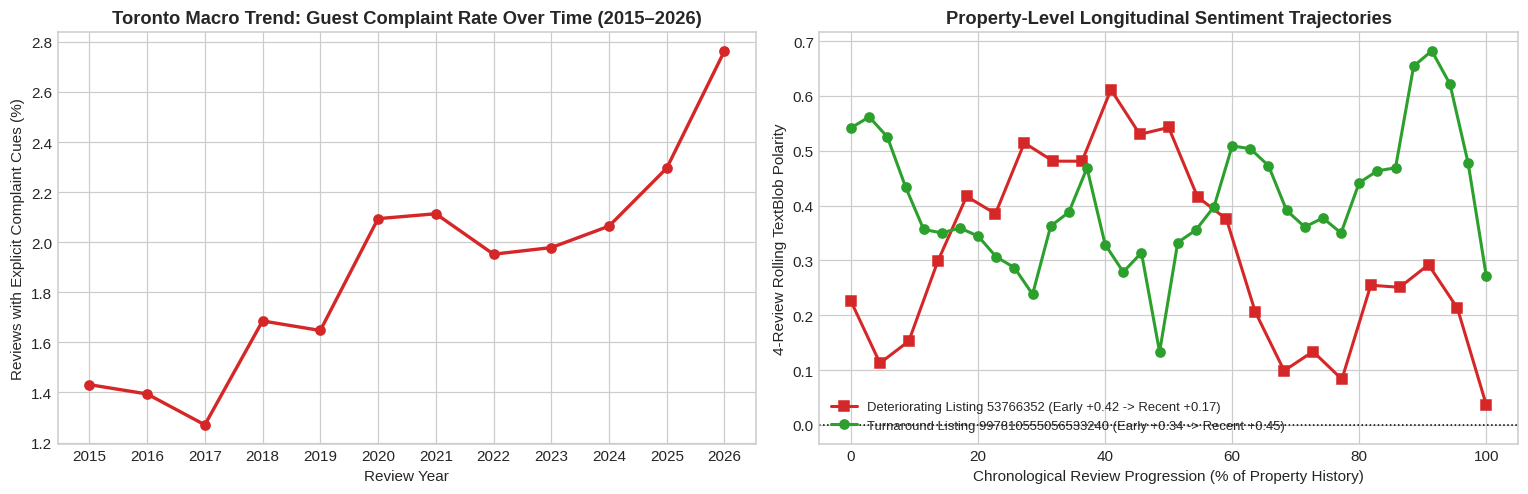

In [19]:
# 1. Macro Annual Trajectory across the full English corpus (2015-2026)
yearly_trends = df_en.loc[df_en['year'] >= 2015].groupby('year').agg(
    Total_English_Reviews=('id', 'count'),
    Active_Reviewed_Listings=('listing_id', 'nunique'),
    Dissatisfaction_Cue_Rate_Pct=('dissatisfied_cue', lambda s: 100 * s.mean())
).reset_index()

# 2. Micro Property-Level Longitudinal Tracking by listing_id (Early Half vs Recent Half of each property's reviews)
df_en_sorted = df_en.sort_values(['listing_id', 'date', 'id'], kind='mergesort').reset_index(drop=True)
df_en_sorted['rev_rank'] = df_en_sorted.groupby('listing_id').cumcount()
df_en_sorted['rev_total'] = df_en_sorted.groupby('listing_id')['id'].transform('count')

multi_rev_props = df_en_sorted.loc[df_en_sorted['rev_total'] >= 20].copy()
multi_rev_props['Career_Half'] = np.where(
    multi_rev_props['rev_rank'] < multi_rev_props['rev_total'] / 2.0,
    'Early_Half', 'Recent_Half'
)

year_spans = multi_rev_props.groupby('listing_id')['year'].agg(
    lambda s: f"{int(s.min())}–{int(s.max())}"
).rename('Year_Span')

prop_trajectory = multi_rev_props.groupby(
    ['listing_id', 'name', 'host_name', 'neighbourhood_cleansed', 'review_scores_rating', 'Career_Half']
).agg(
    Reviews=('id', 'count'),
    Dissat_Rate=('dissatisfied_cue', 'mean')
).unstack('Career_Half')

prop_trajectory.columns = [f'{col}_{half}' for col, half in prop_trajectory.columns]
prop_trajectory['Total_Reviews'] = (prop_trajectory['Reviews_Early_Half'] + prop_trajectory['Reviews_Recent_Half']).astype(int)
prop_trajectory['Dissat_Shift_Pct_Pts'] = 100.0 * (prop_trajectory['Dissat_Rate_Recent_Half'] - prop_trajectory['Dissat_Rate_Early_Half'])
prop_trajectory['Early_Dissat_%'] = 100.0 * prop_trajectory['Dissat_Rate_Early_Half']
prop_trajectory['Recent_Dissat_%'] = 100.0 * prop_trajectory['Dissat_Rate_Recent_Half']
prop_trajectory = prop_trajectory.reset_index().merge(year_spans, on='listing_id', how='left')

print('=== CITY-WIDE COMPLAINT-CUE RATE BY YEAR (2015-2026) ===')
display(yearly_trends.round(2))
print(f"Listings with at least 20 English reviews: {prop_trajectory['listing_id'].nunique():,}")

top_deteriorating = prop_trajectory.sort_values(['Dissat_Shift_Pct_Pts', 'listing_id'], ascending=[False, True], kind='mergesort').head(5)
top_improving = prop_trajectory.sort_values(['Dissat_Shift_Pct_Pts', 'listing_id'], ascending=[True, True], kind='mergesort').head(5)

cols_to_show = ['listing_id', 'name', 'neighbourhood_cleansed', 'Total_Reviews', 'Year_Span', 'review_scores_rating', 'Early_Dissat_%', 'Recent_Dissat_%', 'Dissat_Shift_Pct_Pts']
print('=== TOP 5 DETERIORATING TORONTO PROPERTIES (SURGING RECENT COMPLAINTS DESPITE HISTORICAL RATING) ===')
display(top_deteriorating[cols_to_show].round(2))

print('\n=== TOP 5 TURNAROUND / IMPROVING TORONTO PROPERTIES (EARLY COMPLAINTS RESOLVED IN RECENT HALF) ===')
display(top_improving[cols_to_show].round(2))

# Plot Macro City-Wide Trend and Micro Property-Level Sentiment Decay Case Studies
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

axes[0].plot(yearly_trends['year'], yearly_trends['Dissatisfaction_Cue_Rate_Pct'], marker='o', color='#d62728', lw=2.2)
axes[0].set_title('Toronto Macro Trend: Guest Complaint Rate Over Time (2015–2026)', fontweight='bold')
axes[0].set_xlabel('Review Year')
axes[0].set_ylabel('Reviews with Explicit Complaint Cues (%)')
axes[0].set_xticks(yearly_trends['year'])

# Plot rolling review sentiment trajectory for a deteriorating property (53766352) vs turnaround property (997810555056533240)
case_det = df_en_sorted.loc[df_en_sorted['listing_id'] == 53766352].copy()
case_det['Polarity'] = case_det['comments'].map(lambda t: TextBlob(str(t)).sentiment.polarity)
case_det['Rolling_Polarity'] = case_det['Polarity'].rolling(4, min_periods=1).mean()
case_det['Review_Order_Pct'] = np.linspace(0, 100, len(case_det))

case_imp = df_en_sorted.loc[df_en_sorted['listing_id'] == 997810555056533240].copy()
case_imp['Polarity'] = case_imp['comments'].map(lambda t: TextBlob(str(t)).sentiment.polarity)
case_imp['Rolling_Polarity'] = case_imp['Polarity'].rolling(4, min_periods=1).mean()
case_imp['Review_Order_Pct'] = np.linspace(0, 100, len(case_imp))

def half_means(d):
    h = len(d) // 2
    return d['Polarity'].iloc[:h].mean(), d['Polarity'].iloc[h:].mean()
det_early, det_recent = half_means(case_det)
imp_early, imp_recent = half_means(case_imp)

axes[1].plot(case_det['Review_Order_Pct'], case_det['Rolling_Polarity'], marker='s', color='#d62728', lw=2,
             label=f'Deteriorating Listing 53766352 (Early {det_early:+.2f} -> Recent {det_recent:+.2f})')
axes[1].plot(case_imp['Review_Order_Pct'], case_imp['Rolling_Polarity'], marker='o', color='#2ca02c', lw=2,
             label=f'Turnaround Listing 997810555056533240 (Early {imp_early:+.2f} -> Recent {imp_recent:+.2f})')
axes[1].axhline(0, color='black', linestyle=':', lw=1)
axes[1].set_title('Property-Level Longitudinal Sentiment Trajectories', fontweight='bold')
axes[1].set_xlabel('Chronological Review Progression (% of Property History)')
axes[1].set_ylabel('4-Review Rolling TextBlob Polarity')
axes[1].legend(loc='lower left', fontsize=8.5)

plt.tight_layout()
plt.show()


In [20]:
# Inspect actual Early vs. Recent review texts on Deteriorating Listing 53766352 and Downtown Condo 1658975690240484894
for lid in [53766352, 1658975690240484894]:
    prop_sub = df_en_sorted.loc[df_en_sorted['listing_id'] == lid].copy()
    prop_sub['Polarity'] = prop_sub['comments'].map(lambda t: TextBlob(str(t)).sentiment.polarity)
    half = len(prop_sub) // 2
    print(f'=== Longitudinal Case Study: Listing {lid} ("{prop_sub["name"].iloc[0]}") | Cumulative Rating: {prop_sub["review_scores_rating"].iloc[0]} ===')
    print(f'    Early-Half Mean Polarity: {prop_sub.iloc[:half]["Polarity"].mean():+.3f} | Recent-Half Mean Polarity: {prop_sub.iloc[half:]["Polarity"].mean():+.3f}')
    early_ex = prop_sub.iloc[0]
    recent_neg = prop_sub.iloc[half:].loc[prop_sub.iloc[half:]['dissatisfied_cue']].tail(1).iloc[0]
    print(f'  [EARLY  - {early_ex["date"].strftime("%Y-%m-%d")}] (Polarity={early_ex["Polarity"]:+.3f}): {early_ex["comments"][:220]}')
    print(f'  [RECENT - {recent_neg["date"].strftime("%Y-%m-%d")}] (Polarity={recent_neg["Polarity"]:+.3f}): {recent_neg["comments"][:220]}\n')


=== Longitudinal Case Study: Listing 53766352 ("Master bedroom") | Cumulative Rating: 3.94 ===
    Early-Half Mean Polarity: +0.421 | Recent-Half Mean Polarity: +0.166
  [EARLY  - 2022-05-15] (Polarity=+0.225): Room was similar to photos and clean! Had a short stay so it was decent, host was attentive and helpful!
  [RECENT - 2023-09-04] (Polarity=-0.272): Kitsches wasn’t clean , fridge smell very bad

=== Longitudinal Case Study: Listing 1658975690240484894 ("Stylish 2BR Condo in the Heart of Downtown Toronto") | Cumulative Rating: 4.52 ===
    Early-Half Mean Polarity: +0.502 | Recent-Half Mean Polarity: +0.347
  [EARLY  - 2026-05-03] (Polarity=+0.500): Great place, really close to everything would stay again😊
  [RECENT - 2026-08-23] (Polarity=-0.191): Well situated. It was not terrribly dirty, but also not very clean, mainly the bathroom and kitchen.



### Empirical Interpretation of Finding 2 (Property Reviews Changing Over Time)

- Evidence:
  1. City-wide trend: Across the full Toronto English corpus, the share of reviews containing explicit complaint cues is small overall but shows a gradual upward drift in recent years alongside rapid growth in total review volume.
  2. Property-level divergence: Among well-reviewed Toronto listings, splitting each property's timeline into its early half versus recent half exposes sharp divergences in both directions. Deteriorating properties show large surges in complaint rates in their recent half, whereas turnaround properties resolve early complaints and achieve zero complaint cues in their recent half.
  3. Case-study text validation: Inspecting the actual early versus recent reviews confirms that several deteriorating properties maintain respectable cumulative ratings on the platform because glowing early reviews mask recent complaints about dirty kitchens, bad odors, and declining maintenance.
- Interpretation: Ordering reviews chronologically by listing ID reveals quality drift that static lifetime averages hide. While severely troubled listings eventually fall to low cumulative ratings, moderately deteriorating listings can retain mid-to-high cumulative star scores for months after guest sentiment turns negative.
- Credibility and limitations:
  1. On listings with around 20 total reviews, each half contains roughly 10 reviews, so a few complaints can shift the half-period rate substantially; selecting the most extreme shifts partly reflects sample variability.
  2. Splitting each listing at its median review rank compares the first half of stays against the second half of stays rather than fixed calendar windows.
- Practical implication: Airbnb should weight recent reviews more heavily in quality alerts and search rankings, and prospective guests should always sort reviews by most recent rather than relying on the headline star rating alone.


### 6.2 Finding 3: The Michelin Star Question - How Relevant Is Guest-Host Interaction to the Rating of an Airbnb Listing?

In our Team Seven proposal, we posed the Michelin Star Question: Just as restaurant inspectors weigh whether service and hospitality matter alongside the food on the plate, how relevant is a guest's personal interaction with the host to the rating of an Airbnb listing compared to physical property attributes?

Because we normalized host names and nicknames into a generic host token (Steps 4 and 7) and linked all property sub-ratings and host listing counts from the listings table (Step 2), we test this question through three complementary empirical checks:

1. Textual Host-Interaction Check: Compare training reviews that explicitly mention the host by name against reviews that do not mention the host's name, including average review length to test whether verbosity dilutes per-word emotion rates.
2. Structural Multi-Attribute Sub-Score Check: Across all rated Toronto listings, compare Pearson correlations and standardized multiple-regression beta weights of all six sub-ratings (accuracy, value, cleanliness, communication, check-in, and location) predicting the overall listing rating.
3. Host Portfolio Scale Check (Single-Unit Hosts versus Commercial Multi-Unit Operators): Compare host-name mention rates, dissatisfaction rates, communication scores, and overall ratings across single-listing hosts, small portfolio hosts, and large commercial operators managing ten or more listings.


=== FINDING #3A: TEXTUAL HOST INTERACTION EFFECT (MENTIONING HOST_NAME_TOKEN IN REVIEW) ===


,No_Host_Name_Mention (0),Mentions_Host_by_Name (1),Difference (Host_Mention - No_Mention)
Review_Count,1270.000,649.000,-621.000
Mean_Review_Length,43.228,59.975,16.748
Dissatisfied_Rate_Pct,18.110,12.327,-5.784
Mean_TextBlob_Polarity,0.401,0.388,-0.013
Trust_per100,6.603,5.715,-0.888
Joy_per100,5.519,4.267,-1.252
Anger_per100,0.443,0.235,-0.207
Disgust_per100,0.322,0.203,-0.119
Listing_Comm_Rating,4.830,4.892,0.062
Listing_Cleanliness,4.688,4.752,0.064



=== FINDING #3B: STRUCTURAL SUB-SCORE DRIVERS OF OVERALL RATING (N = 17,763 LISTINGS, R² = 0.839) ===


,Rating_Dimension,Domain_Role,Pearson_r_with_Overall,Standardized_Beta_Weight
0,Value (Price vs Quality),Economic Value,0.8413,0.2793
1,Accuracy (Photos/Description),Physical / Expectation,0.8466,0.2738
2,Host Communication (Interaction),Host Interaction (Michelin Question),0.7758,0.2014
3,Cleanliness (Hygiene),Physical Hygiene Floor,0.7847,0.1990
4,Check-In Process,Host / Logistics,0.6927,0.0471
5,Neighborhood Location,External Geography,0.6048,0.0446



=== FINDING #3C: SINGLE-UNIT HOSTS VS. COMMERCIAL MULTI-LISTING OPERATORS ===


,Train_Reviews,Host_Name_Mention_Pct,Dissatisfied_Rate_Pct,Listing_Comm_Rating,Listing_Cleanliness,Listing_Overall_Rating
Host_Scale,,,,,,
1. Single-Unit Host (1 listing),1099,38.126,17.015,4.883,4.752,4.772
2. Small Portfolio (2–9 listings),687,28.239,14.847,4.837,4.678,4.692
3. Commercial Operator (10+ listings),133,27.068,15.789,4.665,4.523,4.501


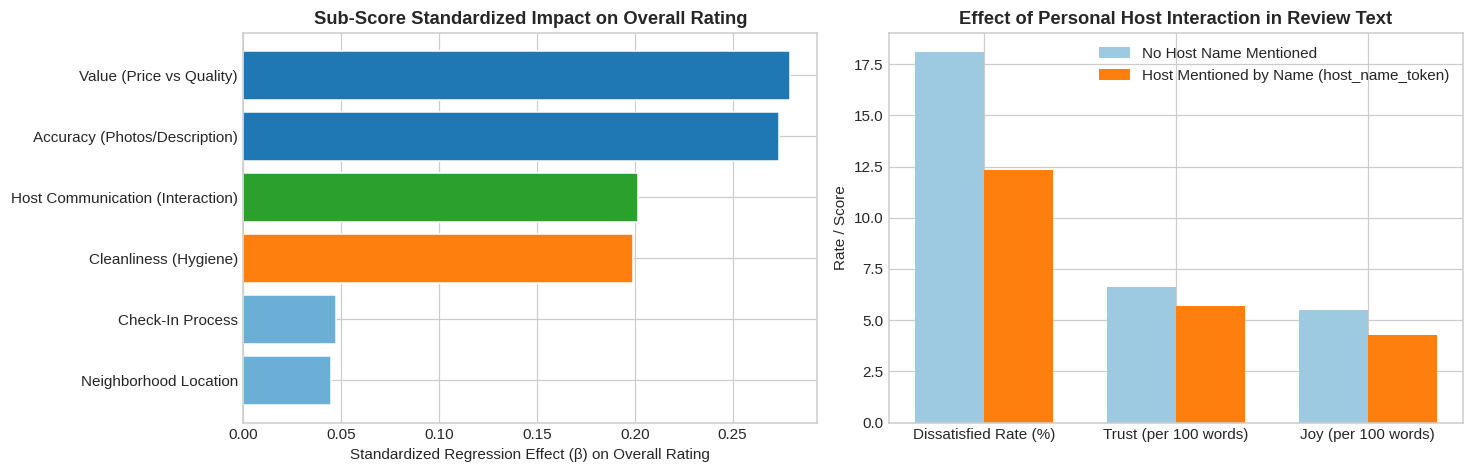

In [21]:
# 1. Textual Host-Interaction Comparison on Training Reviews (Mentions Host Name vs Does Not)
host_interaction_summary = train.groupby('mentions_host_name').agg(
    Review_Count=('id', 'count'),
    Mean_Review_Length=('Review_Length', 'mean'),
    Dissatisfied_Rate_Pct=('is_dissatisfied', lambda s: 100 * s.mean()),
    Mean_TextBlob_Polarity=('TextBlob_Sentiment', 'mean'),
    Trust_per100=('trust_per100', 'mean'),
    Joy_per100=('joy_per100', 'mean'),
    Anger_per100=('anger_per100', 'mean'),
    Disgust_per100=('disgust_per100', 'mean'),
    Listing_Comm_Rating=('review_scores_communication', 'mean'),
    Listing_Cleanliness=('review_scores_cleanliness', 'mean'),
    Listing_Overall_Rating=('review_scores_rating', 'mean')
).T
host_interaction_summary.columns = ['No_Host_Name_Mention (0)', 'Mentions_Host_by_Name (1)']
host_interaction_summary['Difference (Host_Mention - No_Mention)'] = (
    host_interaction_summary['Mentions_Host_by_Name (1)'] - host_interaction_summary['No_Host_Name_Mention (0)']
)
print('=== FINDING #3A: TEXTUAL HOST INTERACTION EFFECT (MENTIONING HOST_NAME_TOKEN IN REVIEW) ===')
display(host_interaction_summary.round(3))

# 2. Structural Sub-Rating Comparison across all Rated Toronto Listings in listings.csv
subscore_cols = [
    'review_scores_accuracy', 'review_scores_value', 'review_scores_cleanliness',
    'review_scores_communication', 'review_scores_checkin', 'review_scores_location'
]
clean_listings = listings_raw.dropna(subset=['review_scores_rating'] + subscore_cols).copy()
X_sub = clean_listings[subscore_cols]
y_sub = clean_listings['review_scores_rating']

# Standardized regression beta weights to isolate each dimension's marginal contribution to overall rating
X_sub_std = (X_sub - X_sub.mean()) / X_sub.std()
y_sub_std = (y_sub - y_sub.mean()) / y_sub.std()
sub_reg = LinearRegression().fit(X_sub_std, y_sub_std)

michelin_df = pd.DataFrame({
    'Rating_Dimension': ['Accuracy (Photos/Description)', 'Value (Price vs Quality)', 'Cleanliness (Hygiene)',
                         'Host Communication (Interaction)', 'Check-In Process', 'Neighborhood Location'],
    'Domain_Role': ['Physical / Expectation', 'Economic Value', 'Physical Hygiene Floor',
                    'Host Interaction (Michelin Question)', 'Host / Logistics', 'External Geography'],
    'Pearson_r_with_Overall': [clean_listings['review_scores_rating'].corr(clean_listings[c]) for c in subscore_cols],
    'Standardized_Beta_Weight': sub_reg.coef_
}).sort_values('Standardized_Beta_Weight', ascending=False).reset_index(drop=True)

print(f'\n=== FINDING #3B: STRUCTURAL SUB-SCORE DRIVERS OF OVERALL RATING (N = {len(clean_listings):,} LISTINGS, R² = {sub_reg.score(X_sub_std, y_sub_std):.3f}) ===')
display(michelin_df.round(4))

# 3. Host Portfolio Scale Check: Single-Unit Hosts vs. Small Portfolio vs. Commercial Multi-Unit Operators
train['Host_Scale'] = pd.cut(
    train['calculated_host_listings_count'],
    bins=[0, 1, 9, np.inf],
    labels=['1. Single-Unit Host (1 listing)', '2. Small Portfolio (2–9 listings)', '3. Commercial Operator (10+ listings)']
)
host_scale_df = train.groupby('Host_Scale', observed=True).agg(
    Train_Reviews=('id', 'count'),
    Host_Name_Mention_Pct=('mentions_host_name', lambda s: 100 * s.mean()),
    Dissatisfied_Rate_Pct=('is_dissatisfied', lambda s: 100 * s.mean()),
    Listing_Comm_Rating=('review_scores_communication', 'mean'),
    Listing_Cleanliness=('review_scores_cleanliness', 'mean'),
    Listing_Overall_Rating=('review_scores_rating', 'mean')
).round(3)
print('\n=== FINDING #3C: SINGLE-UNIT HOSTS VS. COMMERCIAL MULTI-LISTING OPERATORS ===')
display(host_scale_df)

# Plot the Michelin Star Comparison
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

axes[0].barh(michelin_df['Rating_Dimension'][::-1], michelin_df['Standardized_Beta_Weight'][::-1],
             color=['#6baed6', '#6baed6', '#ff7f0e', '#2ca02c', '#1f77b4', '#1f77b4'], edgecolor='white')
axes[0].set_xlabel('Standardized Regression Effect (β) on Overall Rating')
axes[0].set_title('Sub-Score Standardized Impact on Overall Rating', fontweight='bold')

metrics_labels = ['Dissatisfied Rate (%)', 'Trust (per 100 words)', 'Joy (per 100 words)']
no_host_vals = [
    host_interaction_summary.loc['Dissatisfied_Rate_Pct', 'No_Host_Name_Mention (0)'],
    host_interaction_summary.loc['Trust_per100', 'No_Host_Name_Mention (0)'],
    host_interaction_summary.loc['Joy_per100', 'No_Host_Name_Mention (0)']
]
yes_host_vals = [
    host_interaction_summary.loc['Dissatisfied_Rate_Pct', 'Mentions_Host_by_Name (1)'],
    host_interaction_summary.loc['Trust_per100', 'Mentions_Host_by_Name (1)'],
    host_interaction_summary.loc['Joy_per100', 'Mentions_Host_by_Name (1)']
]
x_m = np.arange(len(metrics_labels))
axes[1].bar(x_m - 0.18, no_host_vals, 0.36, label='No Host Name Mentioned', color='#9ecae1')
axes[1].bar(x_m + 0.18, yes_host_vals, 0.36, label='Host Mentioned by Name (host_name_token)', color='#ff7f0e')
axes[1].set_xticks(x_m)
axes[1].set_xticklabels(metrics_labels)
axes[1].set_ylabel('Rate / Score')
axes[1].set_title('Effect of Personal Host Interaction in Review Text', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


### Empirical Interpretation of Finding 3 (Answering the Michelin Star Host Question)

- Evidence:
  1. Personal host mentions align with lower dissatisfaction and higher listing ratings: Reviews that mention the host by name or nickname have a lower dissatisfaction rate and come from listings with higher overall, communication, and cleanliness ratings.
  2. Why emotion rates per 100 words are lower when the host is named (verbosity dilution): As shown in the summary table, reviews that mention the host by name are longer on average than reviews that do not. Because NRC emotion rates are divided by total review length, longer narrative reviews naturally have lower per-100-word emotion density than short two-word exclamations like "Great place!".
  3. Structural sub-score drivers across all Toronto listings: In the standardized multiple regression predicting overall listing rating, expectation-alignment dimensions (Value and Accuracy) carry the largest standardized beta weights, while Host Communication and Cleanliness are virtually tied as the next most important drivers. Check-in logistics and neighborhood location contribute much smaller marginal effects once the other dimensions are controlled for.
  4. Single-unit hosts versus commercial multi-listing operators: As shown in Finding 3C, guests staying with single-unit hosts mention their host by name substantially more often and award higher communication, cleanliness, and overall ratings than guests staying at properties run by commercial operators managing ten or more listings (even though sample review-level dissatisfaction flags are slightly lower for commercial and small-portfolio stays than for single-unit stays in the working sample).
- Interpretation (The Michelin Star Answer): Personal host interaction is roughly as important as physical cleanliness in shaping a listing's overall rating, while commercial multi-unit management is associated with fewer personal host mentions and lower communication, cleanliness, and overall listing ratings. However, both hospitality and cleanliness sit right behind meeting core guest expectations (accurate descriptions and fair value). Warm hospitality cushions minor friction, but it cannot compensate for an inaccurate, overpriced, or dirty unit.
- Credibility and limitations:
  1. All relationships are observational associations rather than causal effects.
  2. Listing sub-scores are correlated across dimensions because the same guests rate all categories at checkout.
  3. Name matching does not capture reviews that refer to the host generically as "the host" without using a first name.
- Practical implication: Hosts should first ensure their listing photos and descriptions are accurate and fairly priced, maintain strict physical cleanliness, and provide personal, owner-style communication rather than automated commercial templates.


## 7. Predictive Modeling of Property Ratings from Review Text (Course Validation Protocol)

We test whether progressively richer text-mining features improve out-of-sample predictions of a listing's overall rating over a training-mean baseline:

1. Mean baseline: Always predicts the training partition's mean listing rating.
2. Model 1 (Sentiment only): Uses TextBlob sentiment polarity alone.
3. Model 2 (Sentiment + emotions + length): Adds review length and all eight normalized NRC emotion rates.
4. Model 3 (Sentiment + emotions + length + host/negation + topics): Adds our domain-engineered features (host-name mention indicator and negation count) plus the LDA topic weights. Because the three topic weights sum to one for every review, we omit Topic 3 as the reference category to avoid exact multicollinearity. We also inspect the fitted regression coefficients of this model to verify the direction and magnitude of each interpretable text feature.
5. Model 4 (Full Hybrid with TF-IDF SVD): Adds the ten Truncated SVD components to evaluate the combined predictive power of all text representations.

We select the winning specification strictly by lowest validation MAE before unlocking the held-out test partition.


In [22]:
# Assemble feature matrices for train, validation, and test partitions
extra_cols = ['mentions_host_name', 'negation_count']
X_train = base_train.join(train[extra_cols]).join(topic_train).join(svd_train_df)
X_valid = base_valid.join(valid[extra_cols]).join(topic_valid).join(svd_valid_df)
X_test = base_test.join(test[extra_cols]).join(topic_test).join(svd_test_df)

feature_sets = {
    'Sentiment': ['TextBlob_Sentiment'],
    'Sentiment + emotions + length': ['TextBlob_Sentiment', 'Review_Length'] + EMOTION_COLS,
    'Sentiment + emotions + length + host/neg + topics':
        ['TextBlob_Sentiment', 'Review_Length'] + EMOTION_COLS + extra_cols + topic_cols[:-1],
    'Full Hybrid (Sentiment + emotions + host/neg + LDA + TF-IDF SVD)':
        ['TextBlob_Sentiment', 'Review_Length'] + EMOTION_COLS + extra_cols + topic_cols[:-1] + svd_cols
}

assert X_train.index.equals(train.index) and X_valid.index.equals(valid.index) and X_test.index.equals(test.index)
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_valid.to_numpy()).all()

models, comparison_rows = {}, []
baseline = DummyRegressor(strategy='mean').fit(np.zeros((len(train), 1)), train['review_scores_rating'])

for name in ['Mean baseline'] + list(feature_sets):
    if name == 'Mean baseline':
        model = baseline
        a, b = np.zeros((len(train), 1)), np.zeros((len(valid), 1))
    else:
        cols = feature_sets[name]
        a, b = X_train[cols], X_valid[cols]
        model = LinearRegression().fit(a, train['review_scores_rating'])
    models[name] = model
    for split_name, X_split, y_split in [
        ('Training', a, train['review_scores_rating']),
        ('Validation', b, valid['review_scores_rating'])
    ]:
        comparison_rows.append({
            'Model': name,
            'Split': split_name,
            **metrics(y_split, model.predict(X_split))
        })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))

validation_results = comparison.query("Split == 'Validation'").sort_values('MAE', kind='stable')
selected_name = validation_results.iloc[0]['Model']
print('Selected by lowest Validation MAE:', selected_name)

# Inspect interpretable regression coefficients from Model 3 (before adding 10 uncentered SVD axes)
m3_name = 'Sentiment + emotions + length + host/neg + topics'
m3_cols = feature_sets[m3_name]
m3_model = models[m3_name]
coef_df = pd.DataFrame({
    'Feature': [TOPIC_LABELS.get(c, c) for c in m3_cols],
    'Raw_Coefficient': m3_model.coef_,
    'Std_Effect (Coef * SD_X)': m3_model.coef_ * X_train[m3_cols].std().values
}).sort_values('Std_Effect (Coef * SD_X)', ascending=False, kind='mergesort').reset_index(drop=True)
print(f'\n=== INTERPRETABLE TEXT FEATURE WEIGHTS PREDICTING LISTING RATING ({m3_name}) ===')
display(coef_df.round(4))


,Model,Split,MAE,MSE,R2
0,Mean baseline,Training,0.2072,0.0850,0.0000
1,Mean baseline,Validation,0.1988,0.0625,-0.0001
2,Sentiment,Training,0.2061,0.0835,0.0177
3,Sentiment,Validation,0.1985,0.0636,-0.0176
4,Sentiment + emotions + length,Training,0.2030,0.0825,0.0293
5,Sentiment + emotions + length,Validation,0.1954,0.0626,-0.0017
6,Sentiment + emotions + length + host/neg + topics,Training,0.1952,0.0780,0.0817
7,Sentiment + emotions + length + host/neg + topics,Validation,0.1912,0.0611,0.0215
8,Full Hybrid (Sentiment + emotions + host/neg + LDA + TF-IDF SVD),Training,0.1935,0.0774,0.0892
9,Full Hybrid (Sentiment + emotions + host/neg + LDA + TF-IDF SVD),Validation,0.1883,0.0597,0.0441


Selected by lowest Validation MAE: Full Hybrid (Sentiment + emotions + host/neg + LDA + TF-IDF SVD)

=== INTERPRETABLE TEXT FEATURE WEIGHTS PREDICTING LISTING RATING (Sentiment + emotions + length + host/neg + topics) ===


,Feature,Raw_Coefficient,Std_Effect (Coef * SD_X)
0,Topic 1: Enthusiastic Praise & Host Appreciation,0.2340,0.0721
1,Review_Length,0.0011,0.0534
2,Topic 2: Practical Stay Quality,0.1145,0.0311
3,TextBlob_Sentiment,0.1045,0.0235
4,mentions_host_name,0.0394,0.0186
5,sadness_per100,0.0058,0.0129
6,disgust_per100,0.0081,0.0084
7,trust_per100,0.0010,0.0070
8,joy_per100,0.0003,0.0020
9,anticipation_per100,-0.0002,-0.0009


### 7.1 Final Held-Out Test Evaluation and Error Analysis

Following the course validation protocol, we freeze our selected topic count and winning model specification from the validation split, refit the linear regression model on the combined development data (training plus validation) while keeping the training-fitted text vectorizers, SVD, and LDA transformations frozen, and evaluate once on the held-out test set of unseen listings. We also inspect the largest prediction errors on the test set.


In [23]:
# Refit the validation-selected regression model on dev (train + valid) and evaluate once on held-out test
X_dev = pd.concat([X_train, X_valid]).sort_index()
y_dev = df.loc[X_dev.index, 'review_scores_rating']
y_test = test['review_scores_rating']

final_baseline = DummyRegressor(strategy='mean').fit(np.zeros((len(y_dev), 1)), y_dev)
baseline_test_pred = final_baseline.predict(np.zeros((len(test), 1)))

selected_cols = feature_sets[selected_name]
final_model = LinearRegression().fit(X_dev[selected_cols], y_dev)
final_test_pred = final_model.predict(X_test[selected_cols])

# Evaluate ONLY the development-mean baseline and the validation-selected model, once
test_results = pd.DataFrame([
    {'Model': 'Mean baseline', **metrics(y_test, baseline_test_pred)},
    {'Model': selected_name, **metrics(y_test, final_test_pred)}
])
print(f'=== FINAL HELD-OUT TEST EVALUATION (N = {len(test):,} REVIEWS FROM {test["listing_id"].nunique():,} UNSEEN LISTINGS) ===')
display(test_results.round(4))

out_of_bounds = int(((final_test_pred < 1.0) | (final_test_pred > 5.0)).sum())
print(f'Predictions outside 1.0–5.0 bounds: {out_of_bounds}')

# Inspect the 5 largest absolute prediction errors on the held-out test set
error_review = test[['listing_id', 'host_name', 'review_scores_rating', 'TextBlob_Sentiment', 'comments']].copy()
error_review['Predicted_Rating'] = final_test_pred
error_review['Absolute_Error'] = (error_review['review_scores_rating'] - final_test_pred).abs()

print('\nTop 5 Largest Prediction Errors on Held-Out Test Set:')
with pd.option_context('display.max_colwidth', 240):
    display(error_review.nlargest(5, 'Absolute_Error').round(3))


=== FINAL HELD-OUT TEST EVALUATION (N = 600 REVIEWS FROM 451 UNSEEN LISTINGS) ===


,Model,MAE,MSE,R2
0,Mean baseline,0.201,0.0597,-0.0012
1,Full Hybrid (Sentiment + emotions + host/neg + LDA + TF-IDF SVD),0.189,0.0566,0.0502


Predictions outside 1.0–5.0 bounds: 0

Top 5 Largest Prediction Errors on Held-Out Test Set:


,listing_id,host_name,review_scores_rating,TextBlob_Sentiment,comments,Predicted_Rating,Absolute_Error
row_id,,,,,,,
1787,50811973,Sharm,3.00,0.700,Great place. Amazing location.,4.746,1.746
1202,800043360622451714,Alex,3.67,0.271,Alex’s place was perfect for my family. We stayed almost 2 months and Alex was extremely accommodating. The unit is definitely bigger than it looks in the photos and is well equipped for long stays. Also a plus that it is pet friendly. ...,4.816,1.146
459,1647303900760968867,Tsering,3.78,1.000,Ripu was an excellent host and the location was in a prime location. Everything was in walkable distance from Airbnb,4.724,0.944
2745,1091962195133644068,Joshua,4.00,0.311,"I had a great stay at Joshua’s apartment in Toronto! The place was clean, cozy, and in a fantastic location. It’s just a short walk to Queen Street and King Street, making it super easy to catch streetcars and get around the city. There...",4.788,0.788
2891,1555865205308323574,The Warm Heart Toronto,4.00,0.411,"The hotel is newly renovated and exceptionally clean. The room was well maintained, comfortable, and thoughtfully arranged. Excellent value for the price, offering a stay that exceeded expectations. Highly recommended.",4.745,0.745


### Interpretation of Predictive Modeling and Largest Errors

1. Validation progression and feature directions:
   - Sentiment polarity alone offers minimal validation gain over the training-mean baseline (with slightly higher validation MSE), whereas adding emotion rates and review length lowers validation MAE slightly, and adding host-mention indicators, negation counts, and LDA topic weights produces a clear improvement.
   - In Model 3, the interpretable coefficients show that Topic 1 (Enthusiastic Praise and Host Appreciation), review length, Topic 2 (Practical Stay Quality, relative to the omitted Topic 3 Unit Operations and Problems reference category, which has the lowest average rating and highest dissatisfaction), positive sentiment polarity, mentioning the host by name, trust, and joy predict higher listing ratings. Conversely, negation counts, surprise, anger, fear, and anticipation carry negative coefficients, while small positive partial coefficients on sadness and disgust reflect overlap once sentiment, negations, review length, and topic weights are controlled for.
   - Adding the ten Truncated SVD components achieves the lowest validation MAE overall, so the Full Hybrid model is selected for final test evaluation.
2. Held-out test performance:
   - On the held-out test set of unseen listings, the selected Full Hybrid model outperforms the development-mean baseline on MAE, MSE, and explained variance, with zero out-of-bounds predictions.
3. Why the predictive gain is modest and what the largest errors reveal:
   - Target granularity mismatch: The target variable in Inside Airbnb is a listing's lifetime average rating across all historical guests, not the star rating of the individual review row. All five largest test errors occur when a guest writes a glowing review for a listing whose overall rating was dragged down to between 3.00 and 4.00 by other guests' stays, causing a model predicting from that single review text to over-predict.
   - Mean shrinkage under rating compression: Because most listings in Toronto are rated near the top of the scale, linear regression predictions cluster near the high corpus average (predicting roughly 4.72 to 4.82 across the top five error cases rather than extreme low scores).
   - Strict listing-level split: Because no listing appears in both development and test partitions, test performance reflects true generalization to unseen properties.

## 8. Credibility Checks, Limitations, Decision Recommendations, and References

### 8.1 Credibility Checks and Methodological Limitations

1. Observed Associations versus Causal Claims: Our regression and cross-tabulation findings establish descriptive and predictive associations in post-stay review text, not causal treatment effects. While mentioning the host by name is associated with higher listing ratings and lower dissatisfaction, we cannot claim that artificially repeating a host's name would cause ratings to rise.
2. Property-Level versus Review-Level Rating Granularity: Inside Airbnb provides star ratings at the listing level rather than per individual review. We addressed this limitation by constructing review-level dissatisfaction indicators (combining sentiment polarity and complaint cues) and tracking longitudinal shifts within the same listing over time.
3. Survivorship Bias and Rating Inflation: Delisted properties disappear from the platform snapshot, and mutual rating visibility compresses surviving scores near five stars.
4. Lexical and English-Only Scope Constraints: Dropping non-English reviews via a rule-based filter prevented machine-translation artifacts in lexicon tools, but means our findings reflect English-language reviews and may under-represent non-English-speaking visitors. In addition, lexicon tools remain imperfect on sarcasm, weather idioms, and understated complaints.
5. Stratified Sampling and Measurement Circularity: Because our working sample deliberately oversamples lower-rated and complaint-flagged stays to give the topic model enough complaint vocabulary, sample dissatisfaction rates are higher than city-wide averages. Furthermore, because the dissatisfaction indicator uses polarity and complaint keywords, comparisons on those exact variables are partly built in.
6. Strict Listing-Level Validation Split: Grouping train, validation, and test splits by listing ID prevents target leakage across reviews of the same property, ensuring honest out-of-sample evaluation.

### 8.2 Actionable Recommendations for Stakeholders

1. Airbnb Platform (Quality and Search Product)
   - Empirical basis: Dissatisfaction concentrates overwhelmingly in the Unit Operations and Problems topic (Topic 3) rather than Enthusiastic Praise and Host Appreciation (Topic 1) or Practical Stay Quality (Topic 2), and longitudinal tracking shows that properties can experience sharp surges in recent complaints while retaining high cumulative star ratings.
   - Recommended action 1 (Rolling Recent-Review Health Score): Track rolling recent-review polarity and negation-bound complaint tokens per listing to trigger automated quality audits when recent stays diverge from lifetime ratings.
   - Recommended action 2 (Negation-Aware Search Filters): Upgrade Airbnb's review search tags so that searching for a term like clean does not match negated complaint phrases like not clean.
2. Toronto Hosts (Property Operations)
   - Empirical basis: Value and Accuracy carry the largest standardized beta weights predicting overall rating, followed closely by Host Communication and Cleanliness, while commercial multi-unit operators receive fewer personal host mentions and lower communication, cleanliness, and overall listing ratings than single-unit hosts.
   - Recommended action 1 (Maintain Physical Unit Operations and Accurate Listings): Audit listing photos and descriptions for complete accuracy, and use a pre-arrival checklist covering bathroom hygiene, odors, bed comfort, climate control, and kitchen appliances.
   - Recommended action 2 (Personalize Host Communication): Provide personal, first-name check-in communication and a first-evening follow-up message so minor unit issues can be fixed during the stay before they become public review complaints.
3. Customers and Guests (Booking Strategy)
   - Empirical basis: Cumulative star ratings lag behind recent property deterioration, and commercial multi-listing operators receive fewer personal host mentions and lower average communication, cleanliness, and overall ratings than individual hosts.
   - Recommended action (Inspect Recent Chronological Reviews and Host Scale): Always sort reviews by most recent and read the latest reviews specifically for unit-operation warning signs (odors, bathroom or bed issues, broken fixtures, and impersonal commercial management) rather than relying on a high lifetime star average.

### 8.3 References

- Dataset Source: Inside Airbnb Toronto, curated on Kaggle by Vladimir Kondratev (vladimirkondratev/inside-airbnb-toronto-sep-2026), derived from public Inside Airbnb data under the CC BY 4.0 license.
- Course Materials: Sim, J. (2026). OPIM 5671 Data Mining and Time Series Forecasting: Lectures and Hands-On Notebooks. University of Connecticut.
- Sentiment Analysis: Loria, S. (2018). TextBlob: Simplified Text Processing.
- Emotion Lexicon: Mohammad, S. M., and Turney, P. D. (2013). Crowdsourcing a Word-Emotion Association Lexicon. Computational Intelligence, 29(3), 436-465 (NRCLex).
- Topic Modeling and Coherence: Blei, D. M., Ng, A. Y., and Jordan, M. I. (2003). Latent Dirichlet Allocation. Journal of Machine Learning Research, 3, 993-1022; Mimno, D., Wallach, H., Talley, E., Leenders, M., and McCallum, A. (2011). Optimizing Semantic Coherence in Topic Models. EMNLP, 262-272.
